In [1]:
import warnings
warnings.filterwarnings("ignore", message="numpy.dtype size changed")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import os
import glob
import random
import tempfile
import gzip
import pylhe
import math
from scipy.optimize import curve_fit
from mpl_toolkits.mplot3d import Axes3D
from auxPlots import  xSecTest, getInfoSMS
from aux import getLHEevents, getDistributions, getInfo, getInfoSummary
from matplotlib.ticker import FixedLocator

pd.option_context('display.max_columns', -1)

pd.options.mode.chained_assignment = None #Disable copy warnings
# plt.style.use('fivethirtyeight') #Set style
# mpl.rcParams.update({'figure.figsize' : (15,10)})  #Set general plotting options
plt.rcParams['figure.max_open_warning'] = 50
plt.rcParams.update({
    "text.usetex": True,
    "font.family": "sans-serif",
    "font.sans-serif": ["Helvetica"]})

plt.rcParams['text.latex.preamble'] = r'\usepackage{amsmath}'

plt.rcParams.update({"savefig.dpi" : 300}) #Figure resolution


#Define plotting style:
sns.set() #Set style
sns.set_style('ticks',{'font.family':'Times New Roman', 'font.serif':'Times New Roman'})
sns.set_context('paper', font_scale=2.0)
cm = plt.colormaps['RdYlBu']

In [2]:
def selectColor(model, process):
    if model == 'VLF EFT':
        return sns.color_palette('Paired')[0]
    elif model == '1-loop VLF':
        return sns.color_palette('Paired')[1]
    elif model == 'Scalar EFT':
        return sns.color_palette('Paired')[2]
    elif model == 'SM':
        return sns.color_palette('Paired')[9]
    else:
        return sns.color_palette('Paired')[3]

In [3]:
def selectColor1(model, process):
    if model == '1-loop VLF':
        if process == r'$q q \to t \bar{t}$':
            return sns.color_palette("RdPu", n_colors=4 + 3)[3]
        else:
            return sns.color_palette("RdPu", n_colors=4 + 3)[4]
    elif model == '1-loop Scalar':
        if process == r'$q q \to t \bar{t}$':
            return sns.color_palette("GnBu", n_colors=4 + 3)[3]
        else:
            return sns.color_palette("GnBu", n_colors=4 + 3)[5]
    else:
        return sns.color_palette('Paired')[3]

# Combining the process to obtain $pp \to t\bar{t}$

In [4]:

files = list(glob.glob(
        '/home/vinicius/EFT_ToyModel/processFolders/Distributions_13_6TeV/bias/*/*/'
        '*1500*1400*.npz'
    ))
data = []
for f in files:
    aux = np.load(f, allow_pickle = True)
    data.append(aux)
print(data)    
data = sorted(data, key=lambda d: (d['mass_params'][0], d['mass_params'][1]))

[NpzFile '/home/vinicius/EFT_ToyModel/processFolders/Distributions_13_6TeV/bias/SMS_1_loop/qq2ttbar_gs4_ydm2/mPsiT_1500_mSDM_1400.npz' with keys: mTT, pT1, pT2, deltaPhi, weights..., NpzFile '/home/vinicius/EFT_ToyModel/processFolders/Distributions_13_6TeV/bias/SMS_1_loop/gg2ttbar_gs4_ydm2/mPsiT_1500_mSDM_1400.npz' with keys: mTT, pT1, pT2, deltaPhi, weights..., NpzFile '/home/vinicius/EFT_ToyModel/processFolders/Distributions_13_6TeV/bias/UV_BSM/qq2ttbar_gs4_ydm2/mPsiT_1500_mSDM_1400.npz' with keys: mTT, pT1, pT2, deltaPhi, weights..., NpzFile '/home/vinicius/EFT_ToyModel/processFolders/Distributions_13_6TeV/bias/UV_BSM/gg2ttbar_gs4_ydm2/mPsiT_1500_mSDM_1400.npz' with keys: mTT, pT1, pT2, deltaPhi, weights...]


In [5]:
#Reading files with bias
sm_files = list(glob.glob('/home/vinicius/EFT_ToyModel/processFolders/Distributions_13_6TeV/bias/sm/pp2ttbar_gs4/*.npz'))
sm_qq_files = list(glob.glob('/home/vinicius/EFT_ToyModel/processFolders/Distributions/bias/sm/qq2ttbar_gs4/*/*.npz'))
print(sm_files, sm_qq_files)
data_sm_exp = []
data_qq_sm_exp = []
#Loading the distributions
for f in  sm_files:
    aux = np.load(f, allow_pickle = True)
    data_sm_exp.append(aux)
        
for f in  sm_qq_files:
    aux = np.load(f, allow_pickle = True)
    data_qq_sm_exp.append(aux)

data_sm_exp = sorted(data_sm_exp, key=lambda d: d['mass_params'][0])

['/home/vinicius/EFT_ToyModel/processFolders/Distributions_13_6TeV/bias/sm/pp2ttbar_gs4/mPsiT_0_mSDM_0.npz'] ['/home/vinicius/EFT_ToyModel/processFolders/Distributions/bias/sm/qq2ttbar_gs4/bias_sm_0_0/mPsiT_0_mSDM_0.npz']


In [6]:
data_NLO = []
for d in data:
    if '1-loop VLF' in d['model'] or '1-loop Scalar' in d['model']:
        data_NLO.append(d)

data_NLO = sorted(data_NLO, key=lambda d: (d['mass_params'][0], d['mass_params'][1]))

In [7]:
for d in data_NLO:
    print(d['nevents'])

915897
1250173
1443950
4558298


### First negative interference in Scalar 

In [8]:
def get_color_by_mass(model, mass):
    mPsiT, mSDM = mass
    
    # --- COLORS FOR VECTOR-LIKE FERMION (VLF) ---
    # Using a progression from bright blue -> dark blue -> purple
    if '1-loop VLF' in model:
        if mPsiT == 500.0 and mSDM == 375.0:
            return 'deepskyblue'   # Bright, distinct blue
        elif mPsiT == 500.0 and mSDM == 475.0:
            return 'dodgerblue'         # Standard pure blue
        elif mPsiT == 600.0 and mSDM == 475.0:
            return 'blue'         # Very dark blue
        elif mPsiT == 1500.0 and mSDM == 1425.0:
            return 'navy'   # Purple-ish blue to separate high mass
        else:
            return 'cornflowerblue' # Fallback

    # --- COLORS FOR SCALAR ---
    # Using a progression from bright green -> dark green -> teal
    elif '1-loop Scalar' in model:
        if mPsiT == 500.0 and mSDM == 375.0:
            return 'chartreuse'    # Bright, distinct green
        elif mPsiT == 500.0 and mSDM == 475.0:
            return 'limegreen'  # Standard deep green
        elif mPsiT == 600.0 and mSDM == 475.0:
            
            return 'forestgreen'    # Very dark green
        elif mPsiT == 1500.0 and mSDM == 1425.0:
            return 'darkgreen'         # Blue-green to separate high mass
        else:
            return 'mediumseagreen' # Fallback
    elif 'Z prime' in model:
        return sns.color_palette('Paired')[5]

    # --- DEFAULT ---
    else:
        return 'black'

In [9]:

files =( #list(glob.glob('/home/vinicius/EFT_ToyModel/processFolders/Distributions/bias/z_prime/*/bias*3000*/*3000*.npz')) 
      list(glob.glob(
        '/home/vinicius/EFT_ToyModel/processFolders/'
        'Distributions_13_6TeV/bias/z_prime/*/'
        'bias_13_6TeV_bench*_3000/*3000*.npz'
    ))
   #+list(glob.glob('/home/vinicius/EFT_ToyModel/processFolders/Distributions/Zprime/20pc_width/*3000*.npz'))
       )
print(files)
#files = list(glob.glob('/home/vinicius/EFT_ToyModel/test/Distributions/*/*/*.npz'))
data_Z = []
#data_sm = []
#Loading the distributions
for f in files:
    aux = np.load(f, allow_pickle = True)
    data_Z.append(aux)

data_Z = sorted(data_Z, key=lambda d: d['mZp'])

['/home/vinicius/EFT_ToyModel/processFolders/Distributions_13_6TeV/bias/z_prime/pp2ttbar_dmv2_qed2/bias_13_6TeV_bench_int_3000/mZp_3000.npz', '/home/vinicius/EFT_ToyModel/processFolders/Distributions_13_6TeV/bias/z_prime/pp2ttbar_dmv4/bias_13_6TeV_bench_3000/mZp_3000.npz']


In [10]:
print(data_Z[0].keys())
print(data_Z[0]['gvu11'])
print(data_Z[0]['gvu33'])
print(data_Z[0]['xsec (pb)'])
print(data_Z[1].keys())
print(data_Z[1]['gvu11'])
print(data_Z[1]['gvu33'])
print(data_Z[1]['xsec (pb)'])


KeysView(NpzFile '/home/vinicius/EFT_ToyModel/processFolders/Distributions_13_6TeV/bias/z_prime/pp2ttbar_dmv2_qed2/bias_13_6TeV_bench_int_3000/mZp_3000.npz' with keys: mTT, pT1, pT2, deltaPhi, weights...)
-0.0116702
0.354165
0.00084286538
KeysView(NpzFile '/home/vinicius/EFT_ToyModel/processFolders/Distributions_13_6TeV/bias/z_prime/pp2ttbar_dmv4/bias_13_6TeV_bench_3000/mZp_3000.npz' with keys: mTT, pT1, pT2, deltaPhi, weights...)
-0.0116702
0.354165
0.0002052354


In [11]:
import math

def calculate_new_couplings(g_q0, g_t0, scale_factor):
    """
    Calculates new Z' couplings to scale the cross section (proportional to g_q * g_t)
    while keeping the total decay width (proportional to 2*g_q^2 + g_t^2) constant.
    """
    # 1. Calculate the invariant width constant K
    K = 2 * (g_q0**2) + (g_t0**2)
    
    # 2. Calculate the target coupling product P
    P = scale_factor * (g_q0 * g_t0)
    
    # 3. Solve the quadratic equation for (g_q^2): 2*(g_q^2)^2 - K*(g_q^2) + P^2 = 0
    discriminant = K**2 - 8 * (P**2)
    
    if discriminant < 0:
        raise ValueError("No physical (real) solution exists for this scaling factor. Width constraint cannot be met.")
        
    g_q_sq_A = (K + math.sqrt(discriminant)) / 4
    g_q_sq_B = (K - math.sqrt(discriminant)) / 4
    
    # 4. Extract the couplings, maintaining the original sign of g_q
    sign_q = -1 if g_q0 < 0 else 1
    
    # Solution A (Typically flips the hierarchy, making it light-quark dominated)
    g_q_A = sign_q * math.sqrt(g_q_sq_A)
    g_t_A = P / g_q_A
    
    # Solution B (Typically preserves the original top-philic hierarchy)
    g_q_B = sign_q * math.sqrt(g_q_sq_B)
    g_t_B = P / g_q_B
    
    return {
        "K_constant": K,
        "P_target": P,
        "Solution_A": {"g_q": g_q_A, "g_t": g_t_A},
        "Solution_B": {"g_q": g_q_B, "g_t": g_t_B}
    }

# ==========================================
# Input Parameters
# ==========================================
g_q_initial = 0.007745886#0.0474898
g_t_initial = 1.585365#0.3481305
scaling = -3.74274#-2.5e-01

# Run Calculation
results = calculate_new_couplings(g_q_initial, g_t_initial, scaling)

# ==========================================
# Print Results
# ==========================================
print(f"Target Coupling Product (P): {results['P_target']:.8f}")
print(f"Width Constant (K = 2*g_q^2 + g_t^2): {results['K_constant']:.8f}\n")

print("--- Solution A (Hierarchy Flipped) ---")
print(f"g_q = {results['Solution_A']['g_q']:.7f}")
print(f"g_t = {results['Solution_A']['g_t']:.7f}")
print(f"Check Width K: {2*results['Solution_A']['g_q']**2 + results['Solution_A']['g_t']**2:.8f}")
print(f"Check Product: {results['Solution_A']['g_q'] * results['Solution_A']['g_t']:.8f}\n")

print("--- Solution B (Hierarchy Preserved) ---")
print(f"g_q = {results['Solution_B']['g_q']:.7f}")
print(f"g_t = {results['Solution_B']['g_t']:.7f}")
print(f"Check Width K: {2*results['Solution_B']['g_q']**2 + results['Solution_B']['g_t']**2:.8f}")
print(f"Check Product: {results['Solution_B']['g_q'] * results['Solution_B']['g_t']:.8f}")

Target Coupling Product (P): -0.04596106
Width Constant (K = 2*g_q^2 + g_t^2): 2.51350218

--- Solution A (Hierarchy Flipped) ---
g_q = 1.1206739
g_t = -0.0410120
Check Width K: 2.51350218
Check Product: -0.04596106

--- Solution B (Hierarchy Preserved) ---
g_q = 0.0289998
g_t = -1.5848723
Check Width K: 2.51350218
Check Product: -0.04596106


SM 522.8723405950276
1-loop Scalar total sum: -0.43942499907308646
1-loop VLF total sum: 0.21659225293411632
Zprime mass masked sum: 0.00037317364626413354, total: 0.0010481008240046683
0.0010481008240046683 -0.00062677285


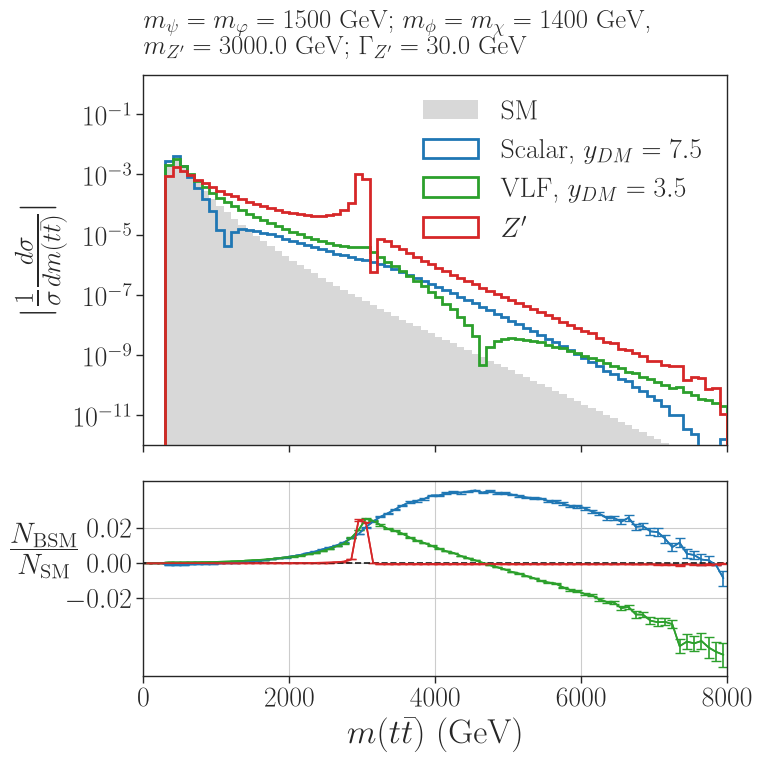

In [12]:
import numpy as np
import matplotlib.pyplot as plt

# ==========================================
# Helper Functions
# ==========================================
def compute_hist(data_list, bins, weight_factor=1.0, z_prime = False, sm = False):
    """Computes the histogram and its statistical error (sqrt of sum of squared weights)."""
    h_total = np.zeros(len(bins) - 1)
    hErr_sq_total = np.zeros(len(bins) - 1)
    
    for i,d in enumerate(data_list):
        current_weight = weight_factor
        if z_prime:
            full_path = d.zip.filename if d.zip is not None else d.fid.name
            if 'qed_int' in full_path:
                current_weight = np.sqrt(weight_factor)
        weights = np.array(d['weights']) * current_weight
        h, _ = np.histogram(d['mTT'], bins=bins, weights=weights)
        hErr_sq, _ = np.histogram(d['mTT'], bins=bins, weights=weights**2)
        h_total += h
        hErr_sq_total += hErr_sq
    if sm:
        h_total = h_total/(i+1)
        hErr_sq_total = hErr_sq_total/(i+1)**2
    return h_total, np.sqrt(hErr_sq_total)

# ==========================================
# General Configuration
# ==========================================
colors = plt.cm.tab10.colors
color_map = {
    'SM': 'gray',
    'VLF': colors[2],
    'Scalar': colors[0],
    'Zprime': colors[3],
    'Zprime_20pc': 'cyan',
    'FakeData': 'black'
}

y_DM_dict = {'1-loop VLF': 3.5, '1-loop Scalar': 7.5}

# ==========================================
# Main Processing Loop
# ==========================================
for i in range(0, len(data_NLO), 4):
    selected = data_NLO[i : i+4]

    # Extract Physics Parameters
    mPsiT, mSDM = selected[0]['mass_params']
    yDM = selected[0]['ydm']
    
    # ------------------------------------------
    # 1. Setup and Binning
    # ------------------------------------------
    fig, axarr = plt.subplots(2, sharex=True, gridspec_kw={'height_ratios': [1.9, 1]}, figsize=(8, 8))
    plt.subplots_adjust(left=0.12, bottom=0.12, right=0.97, hspace=0.1)

 

    bins = np.arange(00., 8100., 100.)
        
    x_centers = (bins[:-1] + bins[1:]) / 2.0  
    
    # Storage for ratio plot
    bsm_hists, bsm_errs, bsm_labels = [], [], []

    # ------------------------------------------
    #  Process Standard Model (SM)
    # ------------------------------------------
    h_sm, hErr_sm = compute_hist(data_sm_exp, bins, sm = True)
    print('SM', np.sum(h_sm))
    
    axarr[0].hist(bins[:-1], weights=np.abs(h_sm), bins=bins, density=True,
                  color=color_map['SM'], alpha=0.3, histtype='step', 
                  linewidth=0.0, fill=True, zorder=0, label='SM')

    # ------------------------------------------
    #  Process NLO BSM Data (Summing qq + gg)
    # ------------------------------------------
    for j in range(0, len(selected), 2):
        d_qq = selected[j]
        d_gg = selected[j+1]
        
        # Format model names
        model_raw = d_qq['model']
        model_name = str(np.atleast_1d(model_raw)[0])
        display_name = model_name.replace('1-loop ', '')
        
        # Get Couplings and scale factor
        val_y_dm = y_DM_dict.get(model_name, 1.0)
        scale_weight = val_y_dm**2 
        
        # Calculate Histograms for qq and gg, then combine
        h_bsm, hErr_bsm = compute_hist([d_qq, d_gg], bins, weight_factor=scale_weight)

        # Store for ratio plot
        bsm_hists.append(h_bsm)
        bsm_errs.append(hErr_bsm)
        bsm_labels.append(display_name)
        
        print(f"{model_raw} total sum: {np.sum(h_bsm)}")

        # Plot Upper Panel
        label_str = rf'{display_name}, $y_{{DM}} = {val_y_dm:.1f}$'
        axarr[0].hist(bins[:-1], weights=np.abs(h_bsm), bins=bins, density=True,
                      color=color_map[display_name], alpha=1.0, histtype='step', 
                      linewidth=2, fill=False, zorder=3, label=label_str)

    # ------------------------------------------
    #  Process Z' 
    # ------------------------------------------
    if len(data_Z) > 0:
        h_z, hErr_z = compute_hist(data_Z, bins, weight_factor=(1.0**2), z_prime = True)
        
        bsm_hists.append(h_z)
        bsm_errs.append(hErr_z)
        bsm_labels.append('Zprime')
        
        mass_mask = (bins[:-1] >= 1000) & (bins[:-1] <= 5000)
        print(f"Zprime mass masked sum: {np.sum(h_z[mass_mask])}, total: {np.sum(h_z)}")
        print(np.sum(h_z),-0.0007418 + 1.1502715e-04)
        axarr[0].hist(bins[:-1], weights=np.abs(h_z), bins=bins, density=True,
                      color=color_map['Zprime'], alpha=1.0, histtype='step', 
                      linewidth=2, fill=False, zorder=3, label=r'$Z^\prime$')

    # ------------------------------------------
    #  Process Ratio (Subplot)
    # ------------------------------------------
    with np.errstate(divide='ignore', invalid='ignore'):
        raw_ratio = np.nan_to_num(np.array(bsm_hists) / h_sm)
        
        # Propagate errors for the ratio (sigma_R / R = sqrt((sigma_A/A)^2 + (sigma_B/B)^2))
        err_bsm_rel = np.nan_to_num(np.array(bsm_errs) / np.array(bsm_hists))
        err_sm_rel = np.nan_to_num(hErr_sm / h_sm)
        ratio_err = np.abs(raw_ratio) * np.sqrt(err_bsm_rel**2 + err_sm_rel**2)

    for k, r in enumerate(raw_ratio):
        plot_color = color_map[bsm_labels[k]]
        axarr[1].errorbar(x_centers, r, yerr=ratio_err[k], color=plot_color, ms=3, capsize=3.5, label=bsm_labels[k])
        axarr[1].plot(x_centers, r, color=plot_color)

    # ------------------------------------------
    #  Plot Formatting & Beautification
    # ------------------------------------------
    
    # Upper Plot Config
    mZp = data_Z[0].get('mZp', 0.0) if len(data_Z) > 0 else 0.0
    
    title_str = (rf'$m_{{\psi}} = m_{{\varphi}} = {mPsiT:.0f}$ GeV; '
                 rf'$m_{{\phi}} = m_\chi = {mSDM:.0f}$ GeV,' + '\n' +
                 rf'$m_{{Z^\prime}} = {mZp:.1f}$ GeV; $\Gamma_{{Z^\prime}} = 30.0$ GeV')
    
    axarr[0].set_title(title_str, loc='left', pad=15)
    axarr[0].legend(framealpha=0.0, ncol=1, loc='upper right', fontsize=20)
    axarr[0].set_yscale('log')
    axarr[0].set_ylabel(r'$|\frac{1}{\sigma}\frac{d \sigma}{d m(t\bar{t})}|$', fontsize=27)
    axarr[0].set_xlim(bins.min(), bins.max())
    axarr[0].set_ylim(1e-12, 2e-0)
    axarr[0].tick_params(axis='both', width=1, labelsize=20)

    # Bottom Plot Config
    axarr[1].axhline(y=0, color='k', linestyle='--')
    axarr[1].set_ylabel(r'$\frac{N_{\mathrm{BSM}}}{ N_{\mathrm{SM}}}$', fontsize=30, rotation=0, labelpad=15) 
    axarr[1].set_xlabel(r'$m(t\bar{t})$ (GeV)', fontsize=25)
    #axarr[1].set_ylim([-0.025, 0.03])
    axarr[1].set_yticks(np.arange(-0.02, 0.03, 0.02))
    axarr[1].grid(True)
    axarr[1].tick_params(axis='both', width=1, labelsize=20)

    # Save and Show
    plt.tight_layout()
    plt.savefig('Dists_comparison_interference.png')
    plt.show()

SM 64.2138522032133
1-loop Scalar total sum: 0.059719680790123436
1-loop VLF total sum: 0.09075726259496943
Zprime mass masked sum: 0.00037317364626413354, total: 0.0010481008240046683


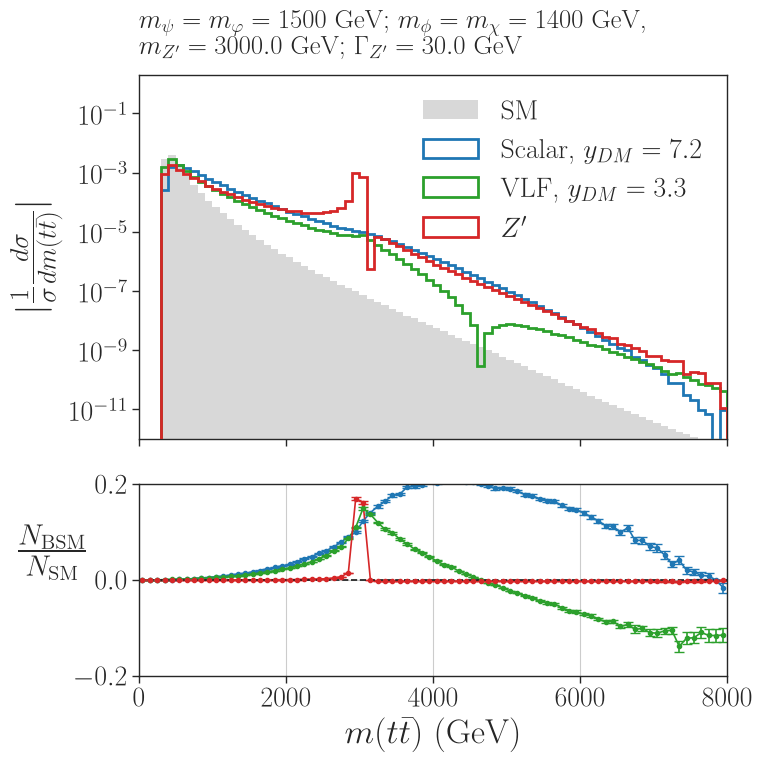

In [13]:
import numpy as np
import matplotlib.pyplot as plt

# ==========================================
# Helper Functions
# ==========================================
def compute_hist(data_list, bins, weight_factor=1.0, z_prime = False):
    """Computes the histogram and its statistical error (sqrt of sum of squared weights)."""
    h_total = np.zeros(len(bins) - 1)
    hErr_sq_total = np.zeros(len(bins) - 1)
    
    for i,d in enumerate(data_list):
        if z_prime and i==1: weight_factor = np.sqrt(weight_factor)
        elif i == 1: break
        weights = np.array(d['weights']) * weight_factor
        h, _ = np.histogram(d['mTT'], bins=bins, weights=weights)
        hErr_sq, _ = np.histogram(d['mTT'], bins=bins, weights=weights**2)
        h_total += h
        hErr_sq_total += hErr_sq
        
    return h_total, np.sqrt(hErr_sq_total)

# ==========================================
# General Configuration
# ==========================================
colors = plt.cm.tab10.colors
color_map = {
    'SM': 'gray',
    'VLF': colors[2],
    'Scalar': colors[0],
    'Zprime': colors[3],
    'Zprime_20pc': 'cyan',
    'FakeData': 'black'
}

y_DM_dict = {'1-loop VLF': 3.3, '1-loop Scalar': 7.2}

# ==========================================
# Main Processing Loop
# ==========================================
for i in range(0, len(data_NLO), 4):
    selected = data_NLO[i : i+4]

    # Extract Physics Parameters
    mPsiT, mSDM = selected[0]['mass_params']
    yDM = selected[0]['ydm']
    
    # ------------------------------------------
    # 1. Setup and Binning
    # ------------------------------------------
    fig, axarr = plt.subplots(2, sharex=True, gridspec_kw={'height_ratios': [1.9, 1]}, figsize=(8, 8))
    plt.subplots_adjust(left=0.12, bottom=0.12, right=0.97, hspace=0.1)

 

    bins = np.arange(00., 8100., 100.)
        
    x_centers = (bins[:-1] + bins[1:]) / 2.0  
    
    # Storage for ratio plot
    bsm_hists, bsm_errs, bsm_labels = [], [], []

    # ------------------------------------------
    #  Process Standard Model (SM)
    # ------------------------------------------
    h_sm, hErr_sm = compute_hist(data_qq_sm_exp, bins)
    print('SM', np.sum(h_sm))
    
    axarr[0].hist(bins[:-1], weights=np.abs(h_sm), bins=bins, density=True,
                  color=color_map['SM'], alpha=0.3, histtype='step', 
                  linewidth=0.0, fill=True, zorder=0, label='SM')

    # ------------------------------------------
    #  Process NLO BSM Data (Summing qq + gg)
    # ------------------------------------------
    for j in range(0, len(selected), 2):
        d_qq = selected[j]
        d_gg = selected[j+1]
        
        # Format model names
        model_raw = d_qq['model']
        model_name = str(np.atleast_1d(model_raw)[0])
        display_name = model_name.replace('1-loop ', '')
        
        # Get Couplings and scale factor
        val_y_dm = y_DM_dict.get(model_name, 1.0)
        scale_weight = val_y_dm**2 
        
        # Calculate Histograms for qq and gg, then combine
        h_bsm, hErr_bsm = compute_hist([d_qq, d_gg], bins, weight_factor=scale_weight)

        # Store for ratio plot
        bsm_hists.append(h_bsm)
        bsm_errs.append(hErr_bsm)
        bsm_labels.append(display_name)
        
        print(f"{model_raw} total sum: {np.sum(h_bsm)}")

        # Plot Upper Panel
        label_str = rf'{display_name}, $y_{{DM}} = {val_y_dm:.1f}$'
        axarr[0].hist(bins[:-1], weights=np.abs(h_bsm), bins=bins, density=True,
                      color=color_map[display_name], alpha=1.0, histtype='step', 
                      linewidth=2, fill=False, zorder=3, label=label_str)

    # ------------------------------------------
    #  Process Z' 
    # ------------------------------------------
    if len(data_Z) > 0:
        h_z, hErr_z = compute_hist(data_Z, bins, weight_factor=(1.0**2), z_prime = True)
        
        bsm_hists.append(h_z)
        bsm_errs.append(hErr_z)
        bsm_labels.append('Zprime')
        
        mass_mask = (bins[:-1] >= 1000) & (bins[:-1] <= 5000)
        print(f"Zprime mass masked sum: {np.sum(h_z[mass_mask])}, total: {np.sum(h_z)}")

        axarr[0].hist(bins[:-1], weights=np.abs(h_z), bins=bins, density=True,
                      color=color_map['Zprime'], alpha=1.0, histtype='step', 
                      linewidth=2, fill=False, zorder=3, label=r'$Z^\prime$')

    # ------------------------------------------
    #  Process Ratio (Subplot)
    # ------------------------------------------
    with np.errstate(divide='ignore', invalid='ignore'):
        raw_ratio = np.nan_to_num(np.array(bsm_hists) / h_sm)
        
        # Propagate errors for the ratio (sigma_R / R = sqrt((sigma_A/A)^2 + (sigma_B/B)^2))
        err_bsm_rel = np.nan_to_num(np.array(bsm_errs) / np.array(bsm_hists))
        err_sm_rel = np.nan_to_num(hErr_sm / h_sm)
        ratio_err = np.abs(raw_ratio) * np.sqrt(err_bsm_rel**2 + err_sm_rel**2)

    for k, r in enumerate(raw_ratio):
        plot_color = color_map[bsm_labels[k]]
        axarr[1].errorbar(x_centers, r, yerr=ratio_err[k], color=plot_color, 
                          fmt='o', ms=3, capsize=3.5, label=bsm_labels[k])
        axarr[1].plot(x_centers, r, color=plot_color)

    # ------------------------------------------
    #  Plot Formatting & Beautification
    # ------------------------------------------
    
    # Upper Plot Config
    mZp = data_Z[0].get('mZp', 0.0) if len(data_Z) > 0 else 0.0
    
    title_str = (rf'$m_{{\psi}} = m_{{\varphi}} = {mPsiT:.0f}$ GeV; '
                 rf'$m_{{\phi}} = m_\chi = {mSDM:.0f}$ GeV,' + '\n' +
                 rf'$m_{{Z^\prime}} = {mZp:.1f}$ GeV; $\Gamma_{{Z^\prime}} = 30.0$ GeV')
    
    axarr[0].set_title(title_str, loc='left', pad=15)
    axarr[0].legend(framealpha=0.0, ncol=1, loc='upper right', fontsize=20)
    axarr[0].set_yscale('log')
    axarr[0].set_ylabel(r'$|\frac{1}{\sigma}\frac{d \sigma}{d m(t\bar{t})}|$', fontsize=27)
    axarr[0].set_xlim(bins.min(), bins.max())
    axarr[0].set_ylim(1e-12, 2e-0)
    axarr[0].tick_params(axis='both', width=1, labelsize=20)

    # Bottom Plot Config
    axarr[1].axhline(y=0, color='k', linestyle='--')
    axarr[1].set_ylabel(r'$\frac{N_{\mathrm{BSM}}}{ N_{\mathrm{SM}}}$', fontsize=30, rotation=0, labelpad=15) 
    axarr[1].set_xlabel(r'$m(t\bar{t})$ (GeV)', fontsize=25)
    axarr[1].set_ylim([-0.025, 0.03])
    axarr[1].set_yticks(np.arange(-0.2, 0.3, 0.2))
    axarr[1].grid(True)
    axarr[1].tick_params(axis='both', width=1, labelsize=20)

    # Save and Show
    plt.tight_layout()
    plt.savefig('Dists_comparison_qq.png')
    plt.show()

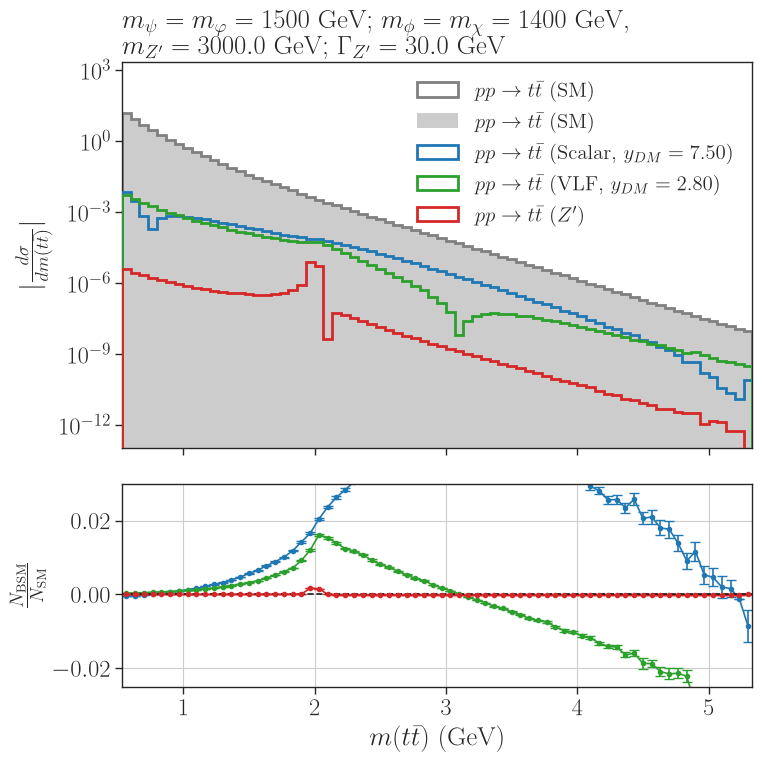

In [14]:

for i in range(0, len(data_NLO), 4):
    selected = data_NLO[i : i+4]

    # BSM masses and couplings
    mPsiT, mSDM = selected[0]['mass_params']
    yDM = selected[0]['ydm']
    
    # --- Setup and Binning ---
    fig, axarr = plt.subplots(2, sharex=True, gridspec_kw={'height_ratios': [1.9, 1]}, figsize=(8, 8))
    plt.subplots_adjust(left=0.12, bottom=0.12, right=0.97, top=None, wspace=None, hspace=0.1)

    if mPsiT < 600:
        bins = np.arange(400., 3000., 50.)
    elif mPsiT < 1000:
        bins = np.arange(500., 4000., 75.)
    else:
        bins = np.arange(800., 8100., 100.)
        
    x = (bins[:-1] + bins[1:]) / 2.0  
    bin_widths = np.diff(bins)
    bins_scaled = bins/1500.0
    x_scaled = x/1500.0
    ##############
    #  Main Plot #
    ##############
    
    pmodels = []
    labels_sm = []
    bsm_hists, bsm_errs, bsm_labels, bsm_colors = [], [], [], []

    # Plotting the SM 
    h_sm_total = np.zeros(len(bins)-1)
    hErr_sm_total_sq = np.zeros(len(bins)-1)
    
    for d in data_sm_exp:
        h, _ = np.histogram(d['mTT'], bins=bins, weights=d['weights'])
        hErr_sq, _ = np.histogram(d['mTT'], bins=bins, weights=np.array(d['weights'])**2)
        h_sm_total += h
        hErr_sm_total_sq += hErr_sq
    
    process = r'$p p \to t \bar{t}$'
    model = 'SM'
    pmodels.append(r'%s (%s)' % (process, model))
    label_sm = pmodels[-1]
    labels_sm.append(label_sm)
        
    integral_sm = np.sum(h_sm_total)
    h_sm = h_sm_total #/ (integral_sm * bin_widths) if integral_sm > 0 else h_sm_total
    hErr_sm = np.sqrt(hErr_sm_total_sq) #/ (integral_sm * bin_widths) if integral_sm > 0 else np.sqrt(hErr_sm_total_sq)
    
    axarr[0].hist(bins_scaled[:-1], weights=np.abs(h_sm), label=label_sm, bins=bins_scaled, density = False,
                  color=color_map['SM'], alpha=1.0, histtype='step', 
                  linewidth=2.0, fill=False, zorder=0)
    axarr[0].hist(bins_scaled[:-1], weights=np.abs(h_sm), label=label_sm, bins=bins_scaled, density = False,
                  color=color_map['SM'], alpha=0.4, histtype='step', 
                  linewidth=0.0, fill=True, zorder=0)

    # Plotting the NLO BSM Data (Summing qq + gg for each model)
    y_DM = {'1-loop VLF': 2.8, '1-loop Scalar': 7.5}
    for j in range(0, len(selected), 2):
        d = selected[j]
        d_next = selected[j+1]
        
        process = r'$p p \to t \bar{t}$'
        model = d['model']
        model_raw = d['model']
        model_name = str(np.atleast_1d(model_raw)[0])
        display_name = model_name.replace('1-loop ', '')
        
        val_y_dm = y_DM.get(model_name, 1.0)
        

        display_name = model_name.replace('1-loop ', '')
        pmodels.append(r'%s (%s, $y_{DM} = %.2f$)' % (process, display_name, val_y_dm))
        label = pmodels[-1]
        
        color = get_color_by_mass(model, (mPsiT, mSDM))
        scale_weight = y_DM.get(model_name, 1.0)**2 
        
        h1, _ = np.histogram(d['mTT'], bins=bins, weights=d['weights'])
        hErr1_sq, _ = np.histogram(d['mTT'], bins=bins, weights=np.array(d['weights'])**2)
        
        h2, _ = np.histogram(d_next['mTT'], bins=bins, weights=d_next['weights'])
        hErr2_sq, _ = np.histogram(d_next['mTT'], bins=bins, weights=np.array(d_next['weights'])**2)
        
        h_bsm_total = (h1 + h2) * scale_weight
        hErr_bsm_total_sq = (hErr1_sq + hErr2_sq)* (scale_weight**2)
        
        integral_bsm = np.sum(h_bsm_total)
        h_bsm = h_bsm_total #/ (integral_bsm * bin_widths) if integral_bsm > 0 else h_bsm_total
        hErr_bsm = np.sqrt(hErr_bsm_total_sq) #/ (integral_bsm * bin_widths) if integral_bsm > 0 else np.sqrt(hErr_bsm_total_sq)

        bsm_hists.append(h_bsm)
        bsm_errs.append(hErr_bsm)
        bsm_labels.append(display_name)
        bsm_colors.append(color)

        axarr[0].hist(bins_scaled[:-1], weights=np.abs(h_bsm), label=label, bins=bins_scaled,
                      color=color_map[display_name], alpha=1.0, histtype='step', density = False,
                      linewidth=2, fill=False, zorder=3)
        #axarr[0].errorbar(x, np.abs(h_bsm), yerr=hErr_bsm, color=color, 
         #                 fmt='none', capsize=3, capthick=1.2, barsabove=True, alpha=1.0)

   
    h_z_total = np.zeros(len(bins)-1)
    hErr_z_total_sq = np.zeros(len(bins)-1)
    model_z = ""
    
    for d in data_Z:
        h, _ = np.histogram(d['mTT'], bins=bins, weights=0.26**2 * d['weights'])
        hErr_sq, _ = np.histogram(d['mTT'], bins=bins, weights=np.array(0.26**2 * d['weights'])**2)
        h_z_total += h
        hErr_z_total_sq += hErr_sq
        model_z = d['model']
        
    if len(data_Z) > 0:
        process = r'$p p \to t \bar{t}$'
        pmodels.append(r'%s (%s)' % (process, r'$Z^\prime$'))
        label_z = pmodels[-1]
        
        color_z = get_color_by_mass(model_z, (mPsiT, mSDM)) 
        
        integral_z = np.sum(h_z_total)
        h_z = h_z_total #/ (integral_z * bin_widths) if integral_z > 0 else h_z_total
        hErr_z = np.sqrt(hErr_z_total_sq) #/ (integral_z * bin_widths) if integral_z > 0 else np.sqrt(hErr_z_total_sq)
        
        bsm_hists.append(h_z)
        bsm_errs.append(hErr_z)
        bsm_labels.append(r'Zprime')
        bsm_colors.append(color_z)
        
        axarr[0].hist(bins_scaled[:-1], weights=np.abs(h_z), label=label_z, bins=bins_scaled,
                      color=color_map['Zprime'], alpha=1.0, histtype='step', density = False,
                      linewidth=2, fill=False, zorder=3)
        #axarr[0].errorbar(x, np.abs(h_z), yerr=hErr_z, color=color_z, 
                         # fmt='none', capsize=3, capthick=1.2, barsabove=True, alpha=1.0)


    ############
    #  SUBPLOT #
    ############
    with np.errstate(divide='ignore', invalid='ignore'):
        # Calculate the raw ratio first to properly calculate the relative error
        raw_ratio = np.nan_to_num(np.array(bsm_hists) / h_sm)
        
        ratio = raw_ratio 
        
        # Propagate the errors for the ratio 
        err_bsm_rel = np.nan_to_num(np.array(bsm_errs) / np.array(bsm_hists))
        err_sm_rel = np.nan_to_num(hErr_sm / h_sm)
        
        ratio_err = np.abs(raw_ratio) * np.sqrt(err_bsm_rel**2 + err_sm_rel**2)


    for k, r in enumerate(ratio):
        # Using errorbar for the ratio points to show the propagated MC uncertainty
        axarr[1].errorbar(x_scaled, r, yerr=ratio_err[k], color=color_map[bsm_labels[k]], fmt='o', ms=3, capsize=3.5, label=bsm_labels[k])
        axarr[1].plot(x_scaled, r, color=color_map[bsm_labels[k]]) # Add a line connecting points


    #################
    #  Plot configs #
    #################
    
    # Safely extract Z' properties
    mZp = data_Z[0].get('mZp', 0.0) if len(data_Z) > 0 else 0.0
    wZp = data_Z[0].get('wZp', 0.0) if len(data_Z) > 0 else 0.0

    # Upper plot
    axarr[0].legend(framealpha=0.0, ncol=1, loc='upper right', fontsize=15)
    axarr[0].set_title(
        (r'$m_{\psi} = m_{\varphi} = %1.0f$ GeV; $m_{\phi} = m_\chi = %1.0f$ GeV, ' + '\n' +
         r'$m_{Z^\prime} = %1.1f$ GeV; $\Gamma_{Z^\prime} = %1.1f$ GeV') % 
        (mPsiT, mSDM, mZp, 30.0), 
        loc='left'
    )
    axarr[0].set_yscale('log')
    axarr[0].set_ylabel(r'$|\frac{d \sigma}{d m(t\bar{t})}|$')
    axarr[0].set_xlim(bins_scaled.min(), bins_scaled.max())
    axarr[0].set_ylim(1e-13, 2e+3)

    # Bottom plot
    axarr[1].axhline(y=0, color='k', linestyle='--') # Baseline is now at 0
    axarr[1].set_ylabel(r'$\frac{N_{\mathrm{BSM}}}{ N_{\mathrm{SM}}}$') 
    axarr[1].set_xlabel(r'$m(t\bar{t})$ (GeV)')
    axarr[1].grid(True)
    #axarr[1].set_yscale('symlog', linthresh = 0.0001)
    axarr[1].set_ylim([-0.03, 0.03])
    #axarr[1].set_yticks(np.arange(-0.05,0.20, 0.05))
    axarr[1].set_yticks(np.arange(-0.02,0.05, 0.02))
    axarr[1].set_ylim([-0.025, 0.03])
    
    
    minor_tick_locations = np.concatenate((np.arange(-100.0, 0.0, 10.0 ), np.arange(-10.0, 1.0, 1.0 ), np.arange(0.0,11.0,1.0 ),
                                          np.arange(10.0, 100.0, 10.0), np.arange(100.0, 1100.0, 100.0),
                                          np.arange(1000.0, 4000.0, 1000.0))) # Add more as needed for your data range
    axarr[1].yaxis.set_minor_locator(FixedLocator(minor_tick_locations))
    
    plt.tight_layout()
    #filename = f"mtt_pp_mPsiT_{int(mPsiT)}_mSDM_{int(mSDM)}_ratio.png"
    plt.savefig('Dists_comparison_interference.png')
    plt.show()

1-loop Scalar -0.4049740799468275
1-loop VLF 0.19254609001777623


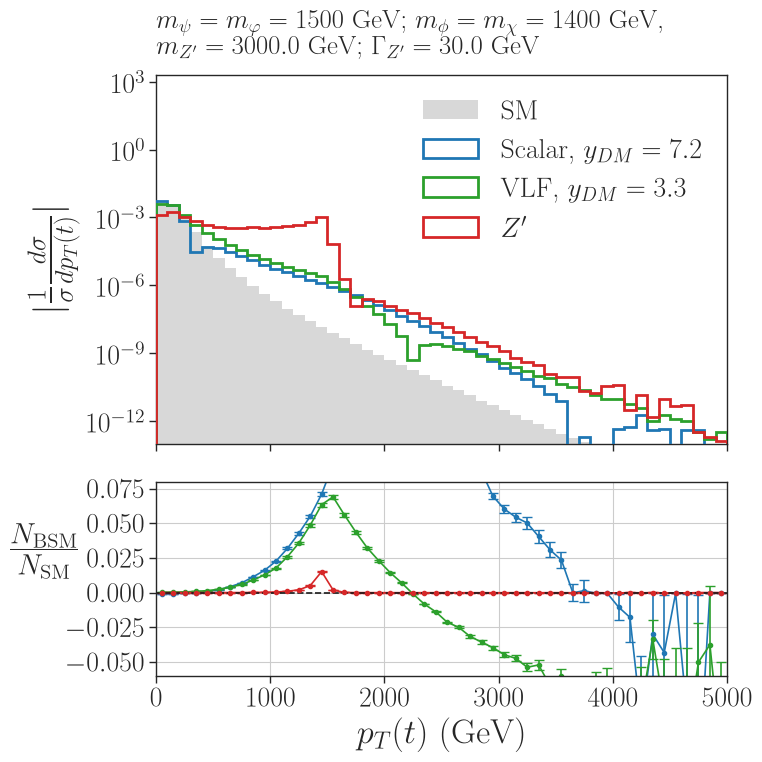

In [20]:
import numpy as np
import matplotlib.pyplot as plt

# ==========================================
# Helper Functions
# ==========================================
def compute_hist(data_list, bins, var='pT', weight_factor=1.0, z_prime=False):
    """Computes the histogram and its statistical error (sqrt of sum of squared weights) for a given variable."""
    h_total = np.zeros(len(bins) - 1)
    hErr_sq_total = np.zeros(len(bins) - 1)
    
    for i, d in enumerate(data_list):
        current_weight_factor = weight_factor
        if z_prime and i == 1: 
            current_weight_factor = np.sqrt(weight_factor)
            
        weights = np.array(d['weights']) * current_weight_factor
        h, _ = np.histogram(d[var], bins=bins, weights=weights)
        hErr_sq, _ = np.histogram(d[var], bins=bins, weights=weights**2)
        
        h_total += h
        hErr_sq_total += hErr_sq
        
    return h_total, np.sqrt(hErr_sq_total)

# ==========================================
# General Configuration
# ==========================================
colors = plt.cm.tab10.colors
color_map = {
    'SM': 'gray',
    'VLF': colors[2],
    'Scalar': colors[0],
    'Zprime': colors[3],
    'Zprime_20pc': 'cyan',
    'FakeData': 'black'
}

# Variable to plot
var = 'pT'

# Couplings for pT
y_DM_dict = {'1-loop VLF': 3.3, '1-loop Scalar': 7.2}

# ==========================================
# Main Processing Loop
# ==========================================
for i in range(0, len(data_NLO), 4):
    selected = data_NLO[i : i+4]

    # Extract Physics Parameters
    mPsiT, mSDM = selected[0]['mass_params']
    yDM = selected[0]['ydm']
    
    # ------------------------------------------
    # 1. Setup and Binning (pT Specific)
    # ------------------------------------------
    fig, axarr = plt.subplots(2, sharex=True, gridspec_kw={'height_ratios': [1.9, 1]}, figsize=(8, 8))
    plt.subplots_adjust(left=0.12, bottom=0.12, right=0.97, hspace=0.1)

    if mPsiT < 600:
        bins = np.arange(400., 3000., 50.)
    elif mPsiT < 1000:
        bins = np.arange(500., 4000., 75.)
    else:
        bins = np.arange(00., 5100., 100.)
        
    x_centers = (bins[:-1] + bins[1:]) / 2.0  
    
    # Storage for ratio plot
    bsm_hists, bsm_errs, bsm_labels = [], [], []

    # ------------------------------------------
    # 2. Process Standard Model (SM)
    # ------------------------------------------
    h_sm, hErr_sm = compute_hist(data_sm_exp, bins, var=var)
    
    axarr[0].hist(bins[:-1], weights=np.abs(h_sm), bins=bins, density=True,
                  color=color_map['SM'], alpha=0.3, histtype='step', 
                  linewidth=0.0, fill=True, zorder=0, label='SM')

    # ------------------------------------------
    # 3. Process NLO BSM Data (Summing qq + gg)
    # ------------------------------------------
    for j in range(0, len(selected), 2):
        d_qq = selected[j]
        d_gg = selected[j+1]
        
        # Format model names
        model_raw = d_qq['model']
        model_name = str(np.atleast_1d(model_raw)[0])
        display_name = model_name.replace('1-loop ', '')
        
        # Get Couplings and scale factor
        val_y_dm = y_DM_dict.get(model_name, 1.0)
        scale_weight = val_y_dm**2 
        
        # Calculate Histograms for qq and gg, then combine
        h_bsm, hErr_bsm = compute_hist([d_qq, d_gg], bins, var=var, weight_factor=scale_weight)

        # Store for ratio plot
        bsm_hists.append(h_bsm)
        bsm_errs.append(hErr_bsm)
        bsm_labels.append(display_name)
        print(model_name, np.sum(h_bsm))
        
        # Plot Upper Panel
        label_str = rf'{display_name}, $y_{{DM}} = {val_y_dm:.1f}$'
        axarr[0].hist(bins[:-1], weights=np.abs(h_bsm), bins=bins, density=True,
                      color=color_map[display_name], alpha=1.0, histtype='step', 
                      linewidth=2, fill=False, zorder=3, label=label_str)

    # ------------------------------------------
    # 4. Process Z' 
    # ------------------------------------------
    if len(data_Z) > 0:
        h_z, hErr_z = compute_hist(data_Z, bins, var=var, weight_factor=(0.26**2), z_prime=True)
        
        bsm_hists.append(h_z)
        bsm_errs.append(hErr_z)
        bsm_labels.append('Zprime')
        
        axarr[0].hist(bins[:-1], weights=np.abs(h_z), bins=bins, density=True,
                      color=color_map['Zprime'], alpha=1.0, histtype='step', 
                      linewidth=2, fill=False, zorder=3, label=r'$Z^\prime$')

    # ------------------------------------------
    # 5. Process Ratio (Subplot)
    # ------------------------------------------
    with np.errstate(divide='ignore', invalid='ignore'):
        raw_ratio = np.nan_to_num(np.array(bsm_hists) / h_sm)
        
        # Propagate errors for the ratio (sigma_R / R = sqrt((sigma_A/A)^2 + (sigma_B/B)^2))
        err_bsm_rel = np.nan_to_num(np.array(bsm_errs) / np.array(bsm_hists))
        err_sm_rel = np.nan_to_num(hErr_sm / h_sm)
        ratio_err = np.abs(raw_ratio) * np.sqrt(err_bsm_rel**2 + err_sm_rel**2)

    for k, r in enumerate(raw_ratio):
        plot_color = color_map[bsm_labels[k]]
        axarr[1].errorbar(x_centers, r, yerr=ratio_err[k], color=plot_color, 
                          fmt='o', ms=3, capsize=3.5, label=bsm_labels[k])
        axarr[1].plot(x_centers, r, color=plot_color)

    # ------------------------------------------
    # 6. Plot Formatting & Beautification
    # ------------------------------------------
    
    # Upper Plot Config
    mZp = data_Z[0].get('mZp', 0.0) if len(data_Z) > 0 else 0.0
    wZp = data_Z[0].get('wZp', 30.0) if len(data_Z) > 0 else 30.0
    
    title_str = (rf'$m_{{\psi}} = m_{{\varphi}} = {mPsiT:.0f}$ GeV; '
                 rf'$m_{{\phi}} = m_\chi = {mSDM:.0f}$ GeV,' + '\n' +
                 rf'$m_{{Z^\prime}} = {mZp:.1f}$ GeV; $\Gamma_{{Z^\prime}} = {wZp:.1f}$ GeV')
    
    axarr[0].set_title(title_str, loc='left', pad=15)
    axarr[0].legend(framealpha=0.0, ncol=1, loc='upper right', fontsize=20)
    axarr[0].set_yscale('log')
    axarr[0].set_ylabel(r'$|\frac{1}{\sigma}\frac{d \sigma}{d p_T(t)}|$', fontsize=27)
    axarr[0].set_xlim(bins.min(), bins.max())
    axarr[0].set_ylim(1e-13, 2e+3)
    axarr[0].tick_params(axis='both', width=1, labelsize=20)


    # Bottom Plot Config
    axarr[1].axhline(y=0, color='k', linestyle='--')
    axarr[1].set_ylabel(r'$\frac{N_{\mathrm{BSM}}}{ N_{\mathrm{SM}}}$', fontsize=30, rotation=0, labelpad=15) 
    axarr[1].set_xlabel(r'$p_T(t)$ (GeV)', fontsize=25)
    axarr[1].set_ylim([-0.06, 0.08]) # Bounding strictly around the yticks
    axarr[1].set_yticks(np.arange(-0.05, 0.08, 0.025))
    axarr[1].grid(True)
    axarr[1].tick_params(axis='both', width=1, labelsize=20)

    # Save and Show
    plt.tight_layout()
    plt.savefig('Dists_comparison_pT.png')
    plt.show()

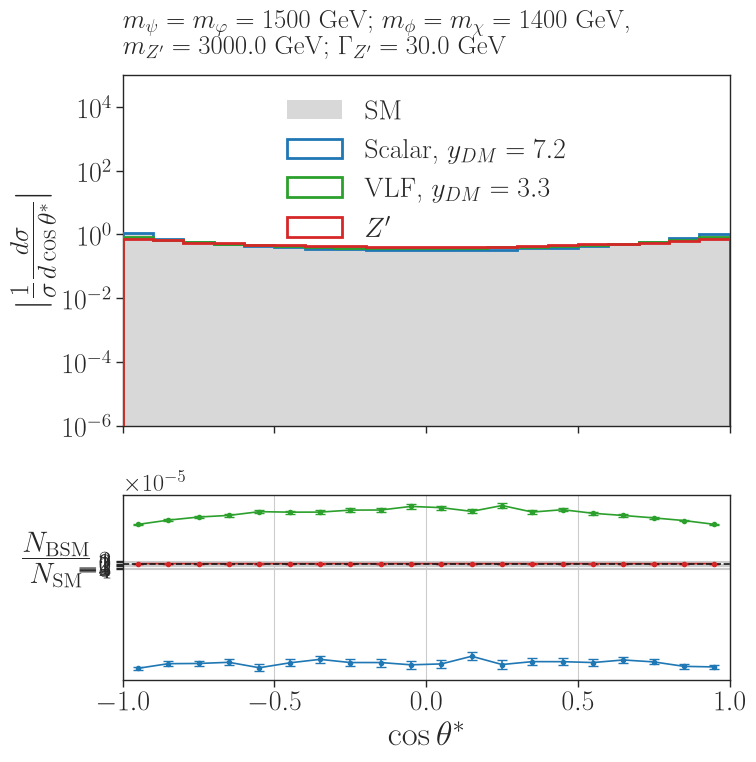

In [21]:
import numpy as np
import matplotlib.pyplot as plt

# ==========================================
# Helper Functions
# ==========================================
def compute_hist(data_list, bins, var='pT', weight_factor=1.0, z_prime=False):
    """Computes the histogram and its statistical error (sqrt of sum of squared weights) for a given variable."""
    h_total = np.zeros(len(bins) - 1)
    hErr_sq_total = np.zeros(len(bins) - 1)
    
    for i, d in enumerate(data_list):
        current_weight_factor = weight_factor
        if z_prime and i == 1: 
            current_weight_factor = np.sqrt(weight_factor)
            
        weights = np.array(d['weights']) * current_weight_factor
        h, _ = np.histogram(d[var], bins=bins, weights=weights)
        hErr_sq, _ = np.histogram(d[var], bins=bins, weights=weights**2)
        
        h_total += h
        hErr_sq_total += hErr_sq
        
    return h_total, np.sqrt(hErr_sq_total)

# ==========================================
# General Configuration
# ==========================================
colors = plt.cm.tab10.colors
color_map = {
    'SM': 'gray',
    'VLF': colors[2],
    'Scalar': colors[0],
    'Zprime': colors[3],
    'Zprime_20pc': 'cyan',
    'FakeData': 'black'
}

# Variable to plot
var = 'cost*'

# Couplings for pT
y_DM_dict = {'1-loop VLF': 3.3, '1-loop Scalar': 7.2}

# ==========================================
# Main Processing Loop
# ==========================================
for i in range(0, len(data_NLO), 4):
    selected = data_NLO[i : i+4]

    # Extract Physics Parameters
    mPsiT, mSDM = selected[0]['mass_params']
    yDM = selected[0]['ydm']
    
    # ------------------------------------------
    # 1. Setup and Binning (pT Specific)
    # ------------------------------------------
    fig, axarr = plt.subplots(2, sharex=True, gridspec_kw={'height_ratios': [1.9, 1]}, figsize=(8, 8))
    plt.subplots_adjust(left=0.12, bottom=0.12, right=0.97, hspace=0.1)

    
    bins = np.linspace(-1., 1., 30)
    bins = np.arange(-1,1.1, 0.1)
    x_centers = (bins[:-1] + bins[1:]) / 2.0  
    
    # Storage for ratio plot
    bsm_hists, bsm_errs, bsm_labels = [], [], []

    # ------------------------------------------
    # 2. Process Standard Model (SM)
    # ------------------------------------------
    h_sm, hErr_sm = compute_hist(data_sm_exp, bins, var=var)
    
    axarr[0].hist(bins[:-1], weights=np.abs(h_sm), bins=bins, density=True,
                  color=color_map['SM'], alpha=0.3, histtype='step', 
                  linewidth=0.0, fill=True, zorder=0, label='SM')

    # ------------------------------------------
    # 3. Process NLO BSM Data (Summing qq + gg)
    # ------------------------------------------
    for j in range(0, len(selected), 2):
        d_qq = selected[j]
        d_gg = selected[j+1]
        
        # Format model names
        model_raw = d_qq['model']
        model_name = str(np.atleast_1d(model_raw)[0])
        display_name = model_name.replace('1-loop ', '')
        
        # Get Couplings and scale factor
        val_y_dm = y_DM_dict.get(model_name, 1.0)
        scale_weight = val_y_dm**2 
        
        # Calculate Histograms for qq and gg, then combine
        h_bsm, hErr_bsm = compute_hist([d_qq, d_gg], bins, var=var, weight_factor=scale_weight)

        # Store for ratio plot
        bsm_hists.append(h_bsm)
        bsm_errs.append(hErr_bsm)
        bsm_labels.append(display_name)
        
        # Plot Upper Panel
        label_str = rf'{display_name}, $y_{{DM}} = {val_y_dm:.1f}$'
        axarr[0].hist(bins[:-1], weights=np.abs(h_bsm), bins=bins, density=True,
                      color=color_map[display_name], alpha=1.0, histtype='step', 
                      linewidth=2, fill=False, zorder=3, label=label_str)

    # ------------------------------------------
    # 4. Process Z' 
    # ------------------------------------------
    if len(data_Z) > 0:
        h_z, hErr_z = compute_hist(data_Z, bins, var=var, weight_factor=(0.26**2), z_prime=True)
        
        bsm_hists.append(h_z)
        bsm_errs.append(hErr_z)
        bsm_labels.append('Zprime')
        
        axarr[0].hist(bins[:-1], weights=np.abs(h_z), bins=bins, density=True,
                      color=color_map['Zprime'], alpha=1.0, histtype='step', 
                      linewidth=2, fill=False, zorder=3, label=r'$Z^\prime$')

    # ------------------------------------------
    # 5. Process Ratio (Subplot)
    # ------------------------------------------
    with np.errstate(divide='ignore', invalid='ignore'):
        raw_ratio = np.nan_to_num(np.array(bsm_hists) / h_sm)
        
        # Propagate errors for the ratio (sigma_R / R = sqrt((sigma_A/A)^2 + (sigma_B/B)^2))
        err_bsm_rel = np.nan_to_num(np.array(bsm_errs) / np.array(bsm_hists))
        err_sm_rel = np.nan_to_num(hErr_sm / h_sm)
        ratio_err = np.abs(raw_ratio) * np.sqrt(err_bsm_rel**2 + err_sm_rel**2)

    for k, r in enumerate(raw_ratio):
        plot_color = color_map[bsm_labels[k]]
        axarr[1].errorbar(x_centers, r, yerr=ratio_err[k], color=plot_color, 
                          fmt='o', ms=3, capsize=3.5, label=bsm_labels[k])
        axarr[1].plot(x_centers, r, color=plot_color)

    # ------------------------------------------
    # 6. Plot Formatting & Beautification
    # ------------------------------------------
    
    # Upper Plot Config
    mZp = data_Z[0].get('mZp', 0.0) if len(data_Z) > 0 else 0.0
    wZp = data_Z[0].get('wZp', 30.0) if len(data_Z) > 0 else 30.0
    
    title_str = (rf'$m_{{\psi}} = m_{{\varphi}} = {mPsiT:.0f}$ GeV; '
                 rf'$m_{{\phi}} = m_\chi = {mSDM:.0f}$ GeV,' + '\n' +
                 rf'$m_{{Z^\prime}} = {mZp:.1f}$ GeV; $\Gamma_{{Z^\prime}} = {wZp:.1f}$ GeV')
    
    axarr[0].set_title(title_str, loc='left', pad=15)
    axarr[0].legend(framealpha=0.0, ncol=1, loc='upper center', fontsize=20)
    axarr[0].set_yscale('log')
    axarr[0].set_ylabel(r'$|\frac{1}{\sigma}\frac{d \sigma}{d \cos{\theta^*}}|$', fontsize=27)
    axarr[0].set_xlim(bins.min(), bins.max())
    axarr[0].set_ylim(1e-6, 1e+5)
    axarr[0].tick_params(axis='both', width=1, labelsize=20)

    # Bottom Plot Config
    axarr[1].axhline(y=0, color='k', linestyle='--')
    axarr[1].set_ylabel(r'$\frac{N_{\mathrm{BSM}}}{ N_{\mathrm{SM}}}$', fontsize=30, rotation=0, labelpad=15) 
    axarr[1].set_xlabel(r'$\cos{\theta^*} $', fontsize=25)
    #axarr[1].set_ylim([-0.06, 0.08]) # Bounding strictly around the yticks
    axarr[1].set_yticks(np.arange(-4e-5,3e-5, 1e-5))
    axarr[1].grid(True)
    axarr[1].tick_params(axis='both', width=1, labelsize=20)
    #axarr[1].set_yscale('symlog', linthresh = 1e-7)

    # Save and Show
    plt.tight_layout()
    plt.savefig('Dists_comparison_cost.png')
    plt.show()

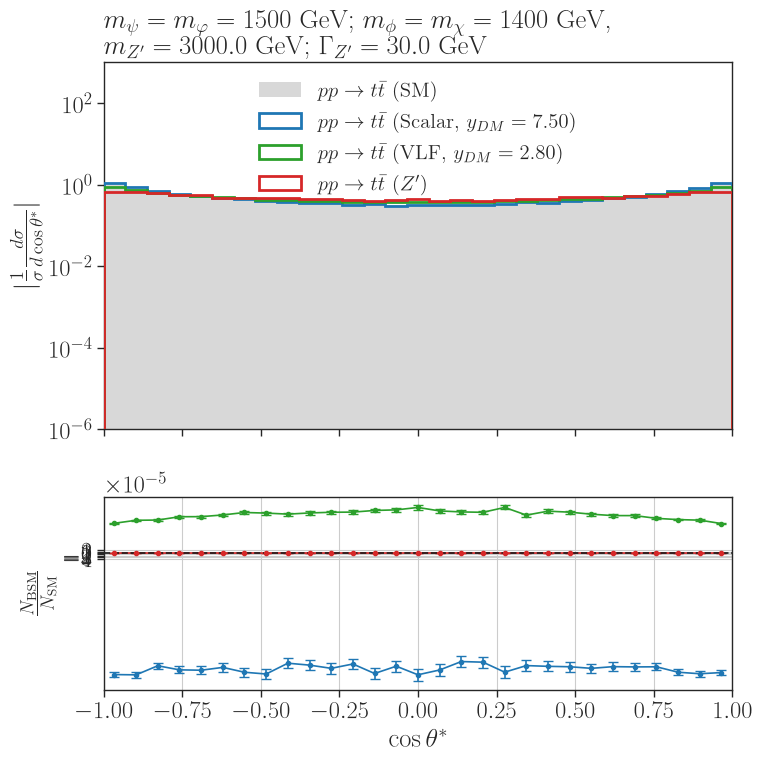

In [22]:
# Loop over the masses configurations. Each mass configuration has 4 items (2 models x 2 processes: qq, gg)

var = 'cost*'
for i in range(0, len(data_NLO), 4):
    selected = data_NLO[i : i+4]

    # BSM masses and couplings
    mPsiT, mSDM = selected[0]['mass_params']
    yDM = selected[0]['ydm']
    
    # --- Setup and Binning ---
    fig, axarr = plt.subplots(2, sharex=True, gridspec_kw={'height_ratios': [1.9, 1]}, figsize=(8, 8))
    plt.subplots_adjust(left=0.12, bottom=0.12, right=0.97, top=None, wspace=None, hspace=0.1)

  
    bins = np.linspace(-1., 1., 30)
        
    x = (bins[:-1] + bins[1:]) / 2.0  
    bin_widths = np.diff(bins)
    bins_scaled = bins
    x_scaled = x
    ##############
    #  Main Plot #
    ##############
    
    pmodels = []
    labels_sm = []
    bsm_hists, bsm_errs, bsm_labels, bsm_colors = [], [], [], []

    # Plotting the SM 
    h_sm_total = np.zeros(len(bins)-1)
    hErr_sm_total_sq = np.zeros(len(bins)-1)
    
    for d in data_sm_exp:
        h, _ = np.histogram(d[var], bins=bins, weights=d['weights'])
        hErr_sq, _ = np.histogram(d[var], bins=bins, weights=np.array(d['weights'])**2)
        h_sm_total += h
        hErr_sm_total_sq += hErr_sq
    
    process = r'$p p \to t \bar{t}$'
    model = 'SM'
    pmodels.append(r'%s (%s)' % (process, model))
    label_sm = pmodels[-1]
    labels_sm.append(label_sm)
        
    integral_sm = np.sum(h_sm_total)
    h_sm = h_sm_total #/ (integral_sm * bin_widths) if integral_sm > 0 else h_sm_total
    hErr_sm = np.sqrt(hErr_sm_total_sq) #/ (integral_sm * bin_widths) if integral_sm > 0 else np.sqrt(hErr_sm_total_sq)
    

    axarr[0].hist(bins_scaled[:-1], weights=np.abs(h_sm), label=label_sm, bins=bins_scaled, density = True,
                  color=color_map['SM'], alpha=0.3, histtype='step', 
                  linewidth=0.0, fill=True, zorder=0)

    # Plotting the NLO BSM Data (Summing qq + gg for each model)
    y_DM = {'1-loop VLF': 2.8, '1-loop Scalar': 7.5}
    for j in range(0, len(selected), 2):
        d = selected[j]
        d_next = selected[j+1]
        
        process = r'$p p \to t \bar{t}$'
        model = d['model']
        model_raw = d['model']
        model_name = str(np.atleast_1d(model_raw)[0])
        display_name = model_name.replace('1-loop ', '')
        
        val_y_dm = y_DM.get(model_name, 1.0)
        

        display_name = model_name.replace('1-loop ', '')
        pmodels.append(r'%s (%s, $y_{DM} = %.2f$)' % (process, display_name, val_y_dm))
        label = pmodels[-1]
        
        color = get_color_by_mass(model, (mPsiT, mSDM))
        scale_weight = y_DM.get(model_name, 1.0)**2 
        
        h1, _ = np.histogram(d[var], bins=bins, weights=d['weights'])
        hErr1_sq, _ = np.histogram(d[var], bins=bins, weights=np.array(d['weights'])**2)
        
        h2, _ = np.histogram(d_next[var], bins=bins, weights=d_next['weights'])
        hErr2_sq, _ = np.histogram(d_next[var], bins=bins, weights=np.array(d_next['weights'])**2)
        
        h_bsm_total = (h1 + h2) * scale_weight
        hErr_bsm_total_sq = (hErr1_sq + hErr2_sq)* (scale_weight**2)
        
        integral_bsm = np.sum(h_bsm_total)
        h_bsm = h_bsm_total #/ (integral_bsm * bin_widths) if integral_bsm > 0 else h_bsm_total
        hErr_bsm = np.sqrt(hErr_bsm_total_sq) #/ (integral_bsm * bin_widths) if integral_bsm > 0 else np.sqrt(hErr_bsm_total_sq)

        bsm_hists.append(h_bsm)
        bsm_errs.append(hErr_bsm)
        bsm_labels.append(display_name)
        bsm_colors.append(color)

        axarr[0].hist(bins_scaled[:-1], weights=np.abs(h_bsm), label=label, bins=bins_scaled,
                      color=color_map[display_name], alpha=1.0, histtype='step', density = True,
                      linewidth=2, fill=False, zorder=3)
        #axarr[0].errorbar(x, np.abs(h_bsm), yerr=hErr_bsm, color=color, 
         #                 fmt='none', capsize=3, capthick=1.2, barsabove=True, alpha=1.0)

   
    h_z_total = np.zeros(len(bins)-1)
    hErr_z_total_sq = np.zeros(len(bins)-1)
    model_z = ""
    
    for d in data_Z:
        h, _ = np.histogram(d[var], bins=bins, weights=0.26**2 * d['weights'])
        hErr_sq, _ = np.histogram(d[var], bins=bins, weights=np.array(0.26**2 * d['weights'])**2)
        h_z_total += h
        hErr_z_total_sq += hErr_sq
        model_z = d['model']
        
    if len(data_Z) > 0:
        process = r'$p p \to t \bar{t}$'
        pmodels.append(r'%s (%s)' % (process, r'$Z^\prime$'))
        label_z = pmodels[-1]
        
        color_z = get_color_by_mass(model_z, (mPsiT, mSDM)) 
        
        integral_z = np.sum(h_z_total)
        h_z = h_z_total #/ (integral_z * bin_widths) if integral_z > 0 else h_z_total
        hErr_z = np.sqrt(hErr_z_total_sq) #/ (integral_z * bin_widths) if integral_z > 0 else np.sqrt(hErr_z_total_sq)
        
        bsm_hists.append(h_z)
        bsm_errs.append(hErr_z)
        bsm_labels.append('Zprime')
        bsm_colors.append(color_z)
        
        axarr[0].hist(bins_scaled[:-1], weights=np.abs(h_z), label=label_z, bins=bins_scaled,
                      color=color_map['Zprime'], alpha=1.0, histtype='step', density = True,
                      linewidth=2, fill=False, zorder=3)
        #axarr[0].errorbar(x, np.abs(h_z), yerr=hErr_z, color=color_z, 
                         # fmt='none', capsize=3, capthick=1.2, barsabove=True, alpha=1.0)


    ############
    #  SUBPLOT #
    ############
    with np.errstate(divide='ignore', invalid='ignore'):
        # Calculate the raw ratio first to properly calculate the relative error
        raw_ratio = np.nan_to_num(np.array(bsm_hists) / h_sm)
        
        ratio = raw_ratio 
        
        # Propagate the errors for the ratio 
        err_bsm_rel = np.nan_to_num(np.array(bsm_errs) / np.array(bsm_hists))
        err_sm_rel = np.nan_to_num(hErr_sm / h_sm)
        
        ratio_err = np.abs(raw_ratio) * np.sqrt(err_bsm_rel**2 + err_sm_rel**2)


    for k, r in enumerate(ratio):
        # Using errorbar for the ratio points to show the propagated MC uncertainty
        axarr[1].errorbar(x_scaled, r, yerr=ratio_err[k], color=color_map[bsm_labels[k]], fmt='o', ms=3, capsize=3.5, label=bsm_labels[k])
        axarr[1].plot(x_scaled, r, color=color_map[bsm_labels[k]]) # Add a line connecting points


    #################
    #  Plot configs #
    #################
    
    # Safely extract Z' properties
    mZp = data_Z[0].get('mZp', 0.0) if len(data_Z) > 0 else 0.0
    wZp = data_Z[0].get('wZp', 0.0) if len(data_Z) > 0 else 0.0

    # Upper plot
    axarr[0].legend(framealpha=0.0, ncol=1, loc='upper center', fontsize=15)
    axarr[0].set_title(
        (r'$m_{\psi} = m_{\varphi} = %1.0f$ GeV; $m_{\phi} = m_\chi = %1.0f$ GeV, ' + '\n' +
         r'$m_{Z^\prime} = %1.1f$ GeV; $\Gamma_{Z^\prime} = %1.1f$ GeV') % 
        (mPsiT, mSDM, mZp, 30.0), 
        loc='left'
    )
    axarr[0].set_yscale('log')
    axarr[0].set_ylabel(r'$|\frac{1}{\sigma}\frac{d \sigma}{d \cos \theta^*}|$')
    axarr[0].set_xlim(bins_scaled.min(), bins_scaled.max())
    axarr[0].set_ylim(1e-6, 1e+3)

    # Bottom plot
    axarr[1].axhline(y=0, color='k', linestyle='--') # Baseline is now at 0
    axarr[1].set_ylabel(r'$\frac{N_{\mathrm{BSM}}}{ N_{\mathrm{SM}}}$') 
    axarr[1].set_xlabel(r'$\cos{\theta^*} $')
    axarr[1].grid(True)
    #axarr[1].set_yscale('symlog', linthresh = 1e-6)
    #axarr[1].set_ylim([-0.03, 0.03])
    #axarr[1].set_yticks(np.arange(-0.05,0.20, 0.05))
    axarr[1].set_yticks(np.arange(-4e-5,3e-5, 1e-5))
    #axarr[1].set_ylim([-0.025, 0.03])
    
    
   
    plt.tight_layout()
    #filename = f"mtt_pp_mPsiT_{int(mPsiT)}_mSDM_{int(mSDM)}_ratio.png"
    plt.savefig('Dists_comparison_cost.png')
    plt.show()

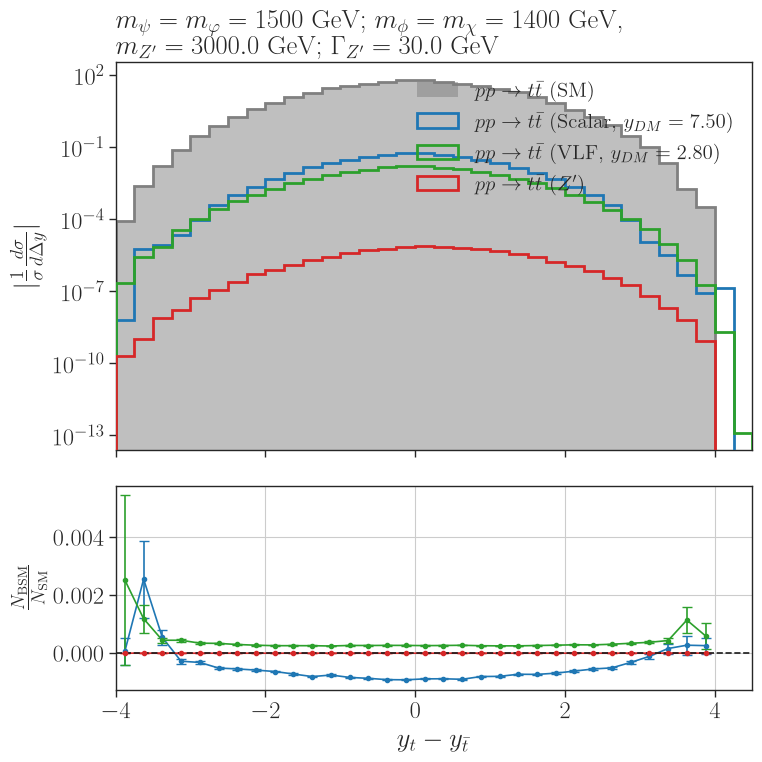

In [23]:
# Loop over the masses configurations. Each mass configuration has 4 items (2 models x 2 processes: qq, gg)

var = 'delta_y'
for i in range(0, len(data_NLO), 4):
    selected = data_NLO[i : i+4]

    # BSM masses and couplings
    mPsiT, mSDM = selected[0]['mass_params']
    yDM = selected[0]['ydm']
    
    # --- Setup and Binning ---
    fig, axarr = plt.subplots(2, sharex=True, gridspec_kw={'height_ratios': [1.9, 1]}, figsize=(8, 8))
    plt.subplots_adjust(left=0.12, bottom=0.12, right=0.97, top=None, wspace=None, hspace=0.1)

  
    bins = np.arange(-4., 4.75, 0.25)
        
    x = (bins[:-1] + bins[1:]) / 2.0  
    bin_widths = np.diff(bins)
    bins_scaled = bins
    x_scaled = x
    ##############
    #  Main Plot #
    ##############
    
    pmodels = []
    labels_sm = []
    bsm_hists, bsm_errs, bsm_labels, bsm_colors = [], [], [], []

    # Plotting the SM 
    h_sm_total = np.zeros(len(bins)-1)
    hErr_sm_total_sq = np.zeros(len(bins)-1)
    
    for d in data_sm_exp:
        h, _ = np.histogram(d[var], bins=bins, weights=d['weights'])
        hErr_sq, _ = np.histogram(d[var], bins=bins, weights=np.array(d['weights'])**2)
        h_sm_total += h
        hErr_sm_total_sq += hErr_sq
    
    process = r'$p p \to t \bar{t}$'
    model = 'SM'
    pmodels.append(r'%s (%s)' % (process, model))
    label_sm = pmodels[-1]
    labels_sm.append(label_sm)
        
    integral_sm = np.sum(h_sm_total)
    h_sm = h_sm_total #/ (integral_sm * bin_widths) if integral_sm > 0 else h_sm_total
    hErr_sm = np.sqrt(hErr_sm_total_sq) #/ (integral_sm * bin_widths) if integral_sm > 0 else np.sqrt(hErr_sm_total_sq)
    
    axarr[0].hist(bins_scaled[:-1], weights=np.abs(h_sm), bins=bins_scaled, density = False,
                  color=color_map['SM'], alpha=1.0, histtype='step', 
                  linewidth=2.0, fill=False, zorder=0)
    axarr[0].hist(bins_scaled[:-1], weights=np.abs(h_sm), label=label_sm, bins=bins_scaled, density = False,
                  color=color_map['SM'], alpha=0.5, histtype='step', 
                  linewidth=0.0, fill=True, zorder=0)

    # Plotting the NLO BSM Data (Summing qq + gg for each model)
    y_DM = {'1-loop VLF': 2.8, '1-loop Scalar': 7.5}
    for j in range(0, len(selected), 2):
        d = selected[j]
        d_next = selected[j+1]
        
        process = r'$p p \to t \bar{t}$'
        model = d['model']
        model_raw = d['model']
        model_name = str(np.atleast_1d(model_raw)[0])
        display_name = model_name.replace('1-loop ', '')
        
        val_y_dm = y_DM.get(model_name, 1.0)
        

        display_name = model_name.replace('1-loop ', '')
        pmodels.append(r'%s (%s, $y_{DM} = %.2f$)' % (process, display_name, val_y_dm))
        label = pmodels[-1]
        
        color = get_color_by_mass(model, (mPsiT, mSDM))
        scale_weight = y_DM.get(model_name, 1.0)**2 
        
        h1, _ = np.histogram(d[var], bins=bins, weights=d['weights'])
        hErr1_sq, _ = np.histogram(d[var], bins=bins, weights=np.array(d['weights'])**2)
        
        h2, _ = np.histogram(d_next[var], bins=bins, weights=d_next['weights'])
        hErr2_sq, _ = np.histogram(d_next[var], bins=bins, weights=np.array(d_next['weights'])**2)
        
        h_bsm_total = (h1 + h2) * scale_weight
        hErr_bsm_total_sq = (hErr1_sq + hErr2_sq)* (scale_weight**2)
        
        integral_bsm = np.sum(h_bsm_total)
        h_bsm = h_bsm_total #/ (integral_bsm * bin_widths) if integral_bsm > 0 else h_bsm_total
        hErr_bsm = np.sqrt(hErr_bsm_total_sq) #/ (integral_bsm * bin_widths) if integral_bsm > 0 else np.sqrt(hErr_bsm_total_sq)

        bsm_hists.append(h_bsm)
        bsm_errs.append(hErr_bsm)
        bsm_labels.append(display_name)
        bsm_colors.append(color)

        axarr[0].hist(bins_scaled[:-1], weights=np.abs(h_bsm), label=label, bins=bins_scaled,
                      color=color_map[display_name], alpha=1.0, histtype='step', density = False,
                      linewidth=2, fill=False, zorder=3)
        #axarr[0].errorbar(x, np.abs(h_bsm), yerr=hErr_bsm, color=color, 
         #                 fmt='none', capsize=3, capthick=1.2, barsabove=True, alpha=1.0)

   
    h_z_total = np.zeros(len(bins)-1)
    hErr_z_total_sq = np.zeros(len(bins)-1)
    model_z = ""
    
    for d in data_Z:
        h, _ = np.histogram(d[var], bins=bins, weights=0.26**2 * d['weights'])
        hErr_sq, _ = np.histogram(d[var], bins=bins, weights=np.array(0.26**2 * d['weights'])**2)
        h_z_total += h
        hErr_z_total_sq += hErr_sq
        model_z = d['model']
        
    if len(data_Z) > 0:
        process = r'$p p \to t \bar{t}$'
        pmodels.append(r'%s (%s)' % (process, r'$Z^\prime$'))
        label_z = pmodels[-1]
        
        color_z = get_color_by_mass(model_z, (mPsiT, mSDM)) 
        
        integral_z = np.sum(h_z_total)
        h_z = h_z_total #/ (integral_z * bin_widths) if integral_z > 0 else h_z_total
        hErr_z = np.sqrt(hErr_z_total_sq) #/ (integral_z * bin_widths) if integral_z > 0 else np.sqrt(hErr_z_total_sq)
        
        bsm_hists.append(h_z)
        bsm_errs.append(hErr_z)
        bsm_labels.append('Zprime')
        bsm_colors.append(color_z)
        
        axarr[0].hist(bins_scaled[:-1], weights=np.abs(h_z), label=label_z, bins=bins_scaled,
                      color=color_map['Zprime'], alpha=1.0, histtype='step', density = False,
                      linewidth=2, fill=False, zorder=3)
        #axarr[0].errorbar(x, np.abs(h_z), yerr=hErr_z, color=color_z, 
                         # fmt='none', capsize=3, capthick=1.2, barsabove=True, alpha=1.0)


    ############
    #  SUBPLOT #
    ############
    with np.errstate(divide='ignore', invalid='ignore'):
        # Calculate the raw ratio first to properly calculate the relative error
        raw_ratio = np.where(h_sm>0,np.array(bsm_hists) / h_sm, np.nan)
        
        ratio = raw_ratio 
        
        # Propagate the errors for the ratio 
        err_bsm_rel = np.nan_to_num(np.array(bsm_errs) / np.array(bsm_hists))
        err_sm_rel = np.nan_to_num(hErr_sm / h_sm)
        
        ratio_err = np.abs(raw_ratio) * np.sqrt(err_bsm_rel**2 + err_sm_rel**2)


    for k, r in enumerate(ratio):
        # Using errorbar for the ratio points to show the propagated MC uncertainty
        axarr[1].errorbar(x_scaled, r, yerr=ratio_err[k], color=color_map[bsm_labels[k]], fmt='o', ms=3, capsize=3.5, label=bsm_labels[k])
        axarr[1].plot(x_scaled, r, color=color_map[bsm_labels[k]]) # Add a line connecting points


    #################
    #  Plot configs #
    #################
    
    # Safely extract Z' properties
    mZp = data_Z[0].get('mZp', 0.0) if len(data_Z) > 0 else 0.0
    wZp = data_Z[0].get('wZp', 0.0) if len(data_Z) > 0 else 0.0

    # Upper plot
    axarr[0].legend(framealpha=0.0, ncol=1, loc='upper right', fontsize=15)
    axarr[0].set_title(
        (r'$m_{\psi} = m_{\varphi} = %1.0f$ GeV; $m_{\phi} = m_\chi = %1.0f$ GeV, ' + '\n' +
         r'$m_{Z^\prime} = %1.1f$ GeV; $\Gamma_{Z^\prime} = %1.1f$ GeV') % 
        (mPsiT, mSDM, mZp, 30.0), 
        loc='left'
    )
    axarr[0].set_yscale('log')
    axarr[0].set_ylabel(r'$|\frac{1}{\sigma}\frac{d \sigma}{d \Delta y}|$')
    axarr[0].set_xlim(bins_scaled.min(), bins_scaled.max())
    #axarr[0].set_ylim(1e-13, 2e+3)

    # Bottom plot
    axarr[1].axhline(y=0, color='k', linestyle='--') # Baseline is now at 0
    axarr[1].set_ylabel(r'$\frac{N_{\mathrm{BSM}}}{ N_{\mathrm{SM}}}$') 
    axarr[1].set_xlabel(r'$y_t - y_{\bar{t}}$')
    axarr[1].grid(True)
    #axarr[1].set_yscale('symlog', linthresh = 0.0001)
    #axarr[1].set_ylim([-0.03, 0.03])
    #axarr[1].set_yticks(np.arange(-0.05,0.20, 0.05))
    #axarr[1].set_yticks(np.arange(-0.02,0.05, 0.02))
    #axarr[1].set_ylim([-0.025, 0.03])
    

    
    plt.tight_layout()
    #filename = f"mtt_pp_mPsiT_{int(mPsiT)}_mSDM_{int(mSDM)}_ratio.png"
    plt.savefig('Dists_comparison_interference.png')
    plt.show()

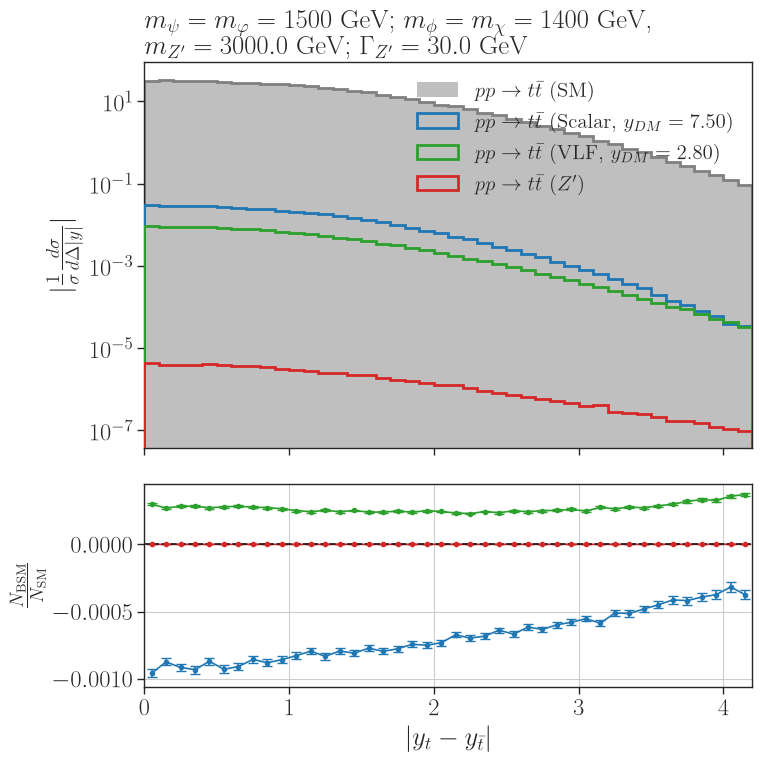

In [24]:
# Loop over the masses configurations. Each mass configuration has 4 items (2 models x 2 processes: qq, gg)

var = 'abs_delta_y'
for i in range(0, len(data_NLO), 4):
    selected = data_NLO[i : i+4]

    # BSM masses and couplings
    mPsiT, mSDM = selected[0]['mass_params']
    yDM = selected[0]['ydm']
    
    # --- Setup and Binning ---
    fig, axarr = plt.subplots(2, sharex=True, gridspec_kw={'height_ratios': [1.9, 1]}, figsize=(8, 8))
    plt.subplots_adjust(left=0.12, bottom=0.12, right=0.97, top=None, wspace=None, hspace=0.1)

  
    bins = np.arange(0., 4.25, 0.1)
        
    x = (bins[:-1] + bins[1:]) / 2.0  
    bin_widths = np.diff(bins)
    bins_scaled = bins
    x_scaled = x
    ##############
    #  Main Plot #
    ##############
    
    pmodels = []
    labels_sm = []
    bsm_hists, bsm_errs, bsm_labels, bsm_colors = [], [], [], []

    # Plotting the SM 
    h_sm_total = np.zeros(len(bins)-1)
    hErr_sm_total_sq = np.zeros(len(bins)-1)
    
    for d in data_sm_exp:
        h, _ = np.histogram(d[var], bins=bins, weights=d['weights'])
        hErr_sq, _ = np.histogram(d[var], bins=bins, weights=np.array(d['weights'])**2)
        h_sm_total += h
        hErr_sm_total_sq += hErr_sq
    
    process = r'$p p \to t \bar{t}$'
    model = 'SM'
    pmodels.append(r'%s (%s)' % (process, model))
    label_sm = pmodels[-1]
    labels_sm.append(label_sm)
        
    integral_sm = np.sum(h_sm_total)
    h_sm = h_sm_total #/ (integral_sm * bin_widths) if integral_sm > 0 else h_sm_total
    hErr_sm = np.sqrt(hErr_sm_total_sq) #/ (integral_sm * bin_widths) if integral_sm > 0 else np.sqrt(hErr_sm_total_sq)
    
    axarr[0].hist(bins_scaled[:-1], weights=np.abs(h_sm), bins=bins_scaled, density = False,
                  color=color_map['SM'], alpha=1.0, histtype='step', 
                  linewidth=2.0, fill=False, zorder=0)
    axarr[0].hist(bins_scaled[:-1], weights=np.abs(h_sm), label=label_sm, bins=bins_scaled, density = False,
                  color=color_map['SM'], alpha=0.5, histtype='step', 
                  linewidth=0.0, fill=True, zorder=0)

    # Plotting the NLO BSM Data (Summing qq + gg for each model)
    y_DM = {'1-loop VLF': 2.8, '1-loop Scalar': 7.5}
    for j in range(0, len(selected), 2):
        d = selected[j]
        d_next = selected[j+1]
        
        process = r'$p p \to t \bar{t}$'
        model = d['model']
        model_raw = d['model']
        model_name = str(np.atleast_1d(model_raw)[0])
        display_name = model_name.replace('1-loop ', '')
        
        val_y_dm = y_DM.get(model_name, 1.0)
        

        display_name = model_name.replace('1-loop ', '')
        pmodels.append(r'%s (%s, $y_{DM} = %.2f$)' % (process, display_name, val_y_dm))
        label = pmodels[-1]
        
        color = get_color_by_mass(model, (mPsiT, mSDM))
        scale_weight = y_DM.get(model_name, 1.0)**2 
        
        h1, _ = np.histogram(d[var], bins=bins, weights=d['weights'])
        hErr1_sq, _ = np.histogram(d[var], bins=bins, weights=np.array(d['weights'])**2)
        
        h2, _ = np.histogram(d_next[var], bins=bins, weights=d_next['weights'])
        hErr2_sq, _ = np.histogram(d_next[var], bins=bins, weights=np.array(d_next['weights'])**2)
        
        h_bsm_total = (h1 + h2) * scale_weight
        hErr_bsm_total_sq = (hErr1_sq + hErr2_sq)* (scale_weight**2)
        
        integral_bsm = np.sum(h_bsm_total)
        h_bsm = h_bsm_total #/ (integral_bsm * bin_widths) if integral_bsm > 0 else h_bsm_total
        hErr_bsm = np.sqrt(hErr_bsm_total_sq) #/ (integral_bsm * bin_widths) if integral_bsm > 0 else np.sqrt(hErr_bsm_total_sq)

        bsm_hists.append(h_bsm)
        bsm_errs.append(hErr_bsm)
        bsm_labels.append(display_name)
        bsm_colors.append(color)

        axarr[0].hist(bins_scaled[:-1], weights=np.abs(h_bsm), label=label, bins=bins_scaled,
                      color=color_map[display_name], alpha=1.0, histtype='step', density = False,
                      linewidth=2, fill=False, zorder=3)
        #axarr[0].errorbar(x, np.abs(h_bsm), yerr=hErr_bsm, color=color, 
         #                 fmt='none', capsize=3, capthick=1.2, barsabove=True, alpha=1.0)

   
    h_z_total = np.zeros(len(bins)-1)
    hErr_z_total_sq = np.zeros(len(bins)-1)
    model_z = ""
    
    for d in data_Z:
        h, _ = np.histogram(d[var], bins=bins, weights=0.26**2 * d['weights'])
        hErr_sq, _ = np.histogram(d[var], bins=bins, weights=np.array(0.26**2 * d['weights'])**2)
        h_z_total += h
        hErr_z_total_sq += hErr_sq
        model_z = d['model']
        
    if len(data_Z) > 0:
        process = r'$p p \to t \bar{t}$'
        pmodels.append(r'%s (%s)' % (process, r'$Z^\prime$'))
        label_z = pmodels[-1]
        
        color_z = get_color_by_mass(model_z, (mPsiT, mSDM)) 
        
        integral_z = np.sum(h_z_total)
        h_z = h_z_total #/ (integral_z * bin_widths) if integral_z > 0 else h_z_total
        hErr_z = np.sqrt(hErr_z_total_sq) #/ (integral_z * bin_widths) if integral_z > 0 else np.sqrt(hErr_z_total_sq)
        
        bsm_hists.append(h_z)
        bsm_errs.append(hErr_z)
        bsm_labels.append('Zprime')
        bsm_colors.append(color_z)
        
        axarr[0].hist(bins_scaled[:-1], weights=np.abs(h_z), label=label_z, bins=bins_scaled,
                      color=color_map['Zprime'], alpha=1.0, histtype='step', density = False,
                      linewidth=2, fill=False, zorder=3)
        #axarr[0].errorbar(x, np.abs(h_z), yerr=hErr_z, color=color_z, 
                         # fmt='none', capsize=3, capthick=1.2, barsabove=True, alpha=1.0)


    ############
    #  SUBPLOT #
    ############
    with np.errstate(divide='ignore', invalid='ignore'):
        # Calculate the raw ratio first to properly calculate the relative error
        raw_ratio = np.where(h_sm>0,np.array(bsm_hists) / h_sm, np.nan)
        
        ratio = raw_ratio 
        
        # Propagate the errors for the ratio 
        err_bsm_rel = np.nan_to_num(np.array(bsm_errs) / np.array(bsm_hists))
        err_sm_rel = np.nan_to_num(hErr_sm / h_sm)
        
        ratio_err = np.abs(raw_ratio) * np.sqrt(err_bsm_rel**2 + err_sm_rel**2)


    for k, r in enumerate(ratio):
        # Using errorbar for the ratio points to show the propagated MC uncertainty
        axarr[1].errorbar(x_scaled, r, yerr=ratio_err[k], color=color_map[bsm_labels[k]], fmt='o', ms=3, capsize=3.5, label=bsm_labels[k])
        axarr[1].plot(x_scaled, r, color=color_map[bsm_labels[k]]) # Add a line connecting points


    #################
    #  Plot configs #
    #################
    
    # Safely extract Z' properties
    mZp = data_Z[0].get('mZp', 0.0) if len(data_Z) > 0 else 0.0
    wZp = data_Z[0].get('wZp', 0.0) if len(data_Z) > 0 else 0.0

    # Upper plot
    axarr[0].legend(framealpha=0.0, ncol=1, loc='upper right', fontsize=15)
    axarr[0].set_title(
        (r'$m_{\psi} = m_{\varphi} = %1.0f$ GeV; $m_{\phi} = m_\chi = %1.0f$ GeV, ' + '\n' +
         r'$m_{Z^\prime} = %1.1f$ GeV; $\Gamma_{Z^\prime} = %1.1f$ GeV') % 
        (mPsiT, mSDM, mZp, 30.0), 
        loc='left'
    )
    axarr[0].set_yscale('log')
    axarr[0].set_ylabel(r'$|\frac{d \sigma}{d m(t\bar{t})}|$')
    axarr[0].set_xlim(bins_scaled.min(), bins_scaled.max())
    #axarr[0].set_ylim(1e-13, 2e+3)

    # Bottom plot
    axarr[0].set_yscale('log')
    axarr[0].set_ylabel(r'$|\frac{1}{\sigma}\frac{d \sigma}{d \Delta |y| }|$')
    axarr[0].set_xlim(bins_scaled.min(), bins_scaled.max())
    #axarr[0].set_ylim(1e-13, 2e+3)

    # Bottom plot
    axarr[1].axhline(y=0, color='k', linestyle='--') # Baseline is now at 0
    axarr[1].set_ylabel(r'$\frac{N_{\mathrm{BSM}}}{ N_{\mathrm{SM}}}$') 
    axarr[1].set_xlabel(r'$|y_t - y_{\bar{t}}|$')
    axarr[1].grid(True)
    #axarr[1].set_yscale('symlog', linthresh = 0.0001)
    #axarr[1].set_ylim([-0.03, 0.03])
    #axarr[1].set_yticks(np.arange(-0.05,0.20, 0.05))
    #axarr[1].set_yticks(np.arange(-0.02,0.05, 0.02))
    #axarr[1].set_ylim([-0.025, 0.03])
    

    
    plt.tight_layout()
    #filename = f"mtt_pp_mPsiT_{int(mPsiT)}_mSDM_{int(mSDM)}_ratio.png"
    plt.savefig('Dists_comparison_interference.png')
    plt.show()

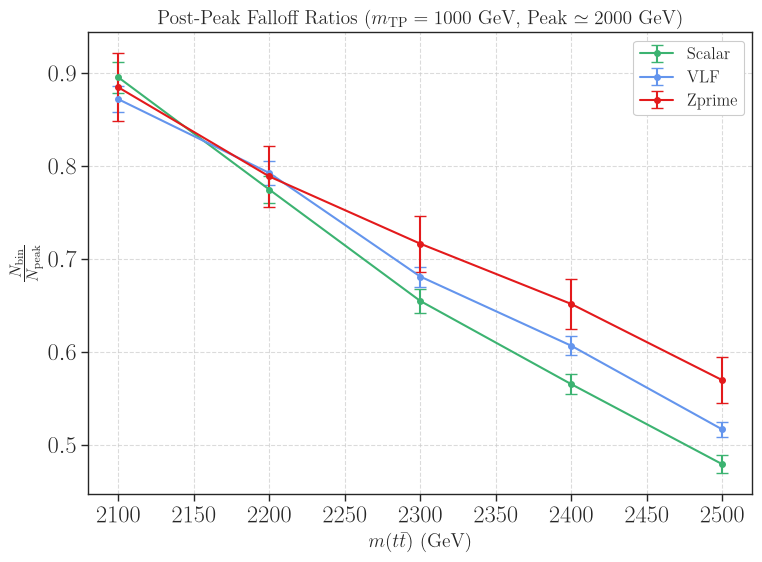

In [25]:
mTP = 1000.0 #GeV
peak = 2.0*mTP
bins = np.arange(450., 5500., 100.)
b_peak = 0
i=0
#Finding the bin where the peak is 
while (peak > bins[i] and i<=len(bins)):
    b_peak = i
    i+=1
ratios = []
ratios_err = []
#Computing the ratios
for i, h in enumerate(bsm_hists):
    aux = []
    err = []
    for j in range(b_peak + 1, b_peak + 6):
        aux.append(h[j]/h[b_peak])
        #propagasting the error through the ratio
        err.append(abs(h[j]/h[b_peak]*np.sqrt((bsm_errs[i][j]/h[j])**2 + (bsm_errs[i][b_peak]/h[b_peak])**2)))
    ratios.append(aux)
    ratios_err.append(err)
#Plotting the ratios for each models
# ==========================================
# Plotting the ratios for each model
# ==========================================

# Calculate the bin centers for the x-axis
x_centers = [(bins[j] + bins[j+1]) / 2.0 for j in range(b_peak + 1, b_peak + 6)]

fig, ax = plt.subplots(figsize=(8, 6))

# Loop over the calculated ratios to plot them
for k in range(len(ratios)):
    # Assuming 'bsm_labels' and 'bsm_colors' are defined in your broader script
    # If not, it safely falls back to generic labels
    label = bsm_labels[k] if 'bsm_labels' in locals() else f"Model {k+1}"
    color = bsm_colors[k] if 'bsm_colors' in locals() else None
    
    ax.errorbar(x_centers, ratios[k], yerr=ratios_err[k], fmt='o-', 
                capsize=4, label=label, color=color, markersize=4, linewidth=1.5)

# Formatting the plot to match the style of your previous physics plots
ax.set_xlabel(r'$m(t\bar{t})$ (GeV)', fontsize=14)
ax.set_ylabel(r'$\frac{N_{\mathrm{bin}}}{N_{\mathrm{peak}}}$', fontsize=16)
ax.set_title(r'Post-Peak Falloff Ratios ($m_{\mathrm{TP}} = 1000$ GeV, Peak $\simeq 2000$ GeV)', fontsize=14)

ax.grid(True, linestyle='--', alpha=0.7)
ax.legend(fontsize=12, framealpha=1.0)

# Optional: Set y-scale to logarithmic if the falloff is very steep
# ax.set_yscale('log')

plt.tight_layout()
#plt.savefig('Post_Peak_Ratios.png', dpi=300)
plt.show()

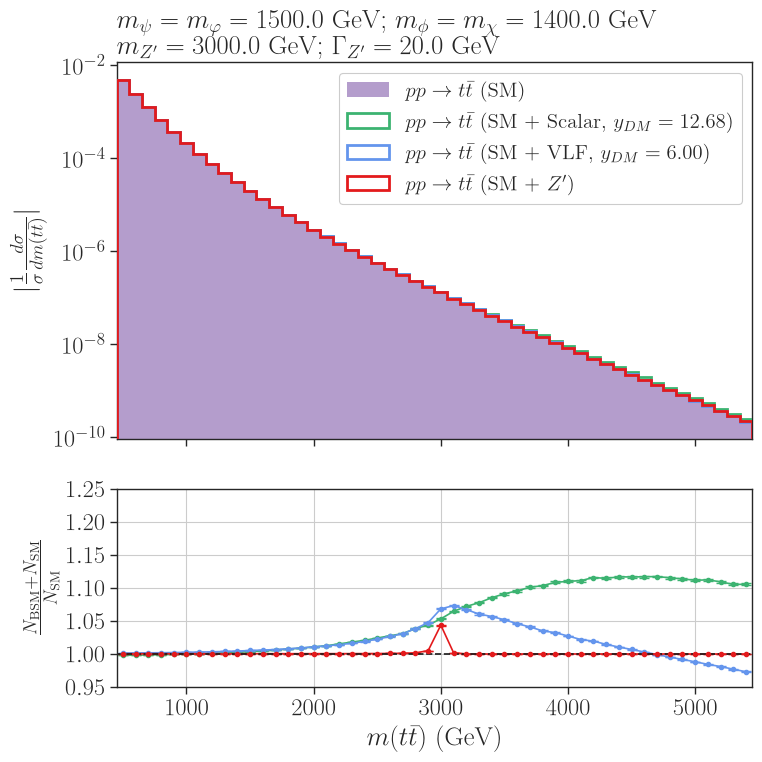

In [26]:


# Loop over the masses configurations. Each mass configuration has 4 items (2 models x 2 processes: qq, gg)
for i in range(0, len(data_NLO), 4):
    selected = data_NLO[i : i+4]

    # BSM masses and couplings
    mPsiT, mSDM = selected[0]['mass_params']
    yDM = selected[0]['ydm']
    
    # --- Setup and Binning ---
    fig, axarr = plt.subplots(2, sharex=True, gridspec_kw={'height_ratios': [1.9, 1]}, figsize=(8, 8))
    plt.subplots_adjust(left=0.12, bottom=0.12, right=0.97, top=None, wspace=None, hspace=0.1)

    if mPsiT < 600:
        bins = np.arange(400., 3000., 50.)
    elif mPsiT < 1000:
        bins = np.arange(500., 4000., 75.)
    else:
        bins = np.arange(450., 5500., 100.)
        
    x = (bins[:-1] + bins[1:]) / 2.0  
    bin_widths = np.diff(bins)

    ##############
    #  Main Plot #
    ##############
    
    pmodels = []
    labels_sm = []
    
    bsm_hists, bsm_histsErr = [], []
    bsm_ratios, bsm_ratio_errs, bsm_labels, bsm_colors = [], [], [], []

    # ==========================================
    # 1 Plotting and Storing the SM (Raw Data)
    # ==========================================
    h_sm_raw = np.zeros(len(bins)-1)
    hErr_sm_raw_sq = np.zeros(len(bins)-1)
    
    for d in data_sm_exp:
        h, _ = np.histogram(d['mTT'], bins=bins, weights=d['weights'])
        hErr_sq, _ = np.histogram(d['mTT'], bins=bins, weights=np.array(d['weights'])**2)
        h_sm_raw += h
        hErr_sm_raw_sq += hErr_sq
    
    process = r'$p p \to t \bar{t}$'
    model = 'SM'
    pmodels.append(r'%s (%s)' % (process, model))
    label_sm = pmodels[-1]
    labels_sm.append(label_sm)
        
    # Density Normalization for SM
    integral_sm = np.sum(h_sm_raw)
    h_sm = h_sm_raw #/ (integral_sm * bin_widths) if integral_sm > 0 else h_sm_raw
    hErr_sm = np.sqrt(hErr_sm_raw_sq) #/ (integral_sm * bin_widths) if integral_sm > 0 else np.sqrt(hErr_sm_raw_sq)
    
    axarr[0].hist(bins[:-1], weights=np.abs(h_sm), label=label_sm, bins=bins, density=True,
                  color=sns.color_palette('Paired')[9], alpha=0.5, histtype='step', 
                  linewidth=0, fill=True, zorder=0)

    # ==========================================
    #  Plotting the NLO BSM Data (SM + BSM)
    # ==========================================
    y_DM = {'1-loop VLF': 6.0, '1-loop Scalar': 1.268000e+01}
    for j in range(0, len(selected), 2):
        d = selected[j]
        d_next = selected[j+1]
        
        process = r'$p p \to t \bar{t}$'
        
        model_raw = d['model']
        model_name = str(np.atleast_1d(model_raw)[0])
        
        val_y_dm = y_DM.get(model_name, 1.0)
        

        display_name = model_name.replace('1-loop ', '')
        pmodels.append(r'%s (SM + %s, $y_{DM} = %.2f$)' % (process, display_name, val_y_dm))
        label = pmodels[-1]
        
        color = get_color_by_mass(model_name, (mPsiT, mSDM))
        
        h1, _ = np.histogram(d['mTT'], bins=bins, weights=d['weights'])
        hErr1_sq, _ = np.histogram(d['mTT'], bins=bins, weights=np.array(d['weights'])**2)
        
        h2, _ = np.histogram(d_next['mTT'], bins=bins, weights=d_next['weights'])
        hErr2_sq, _ = np.histogram(d_next['mTT'], bins=bins, weights=np.array(d_next['weights'])**2)
        
        # Summing BSM and SM Raw Data
        scale_weight = y_DM.get(model_name, 1.0)**2 
        
        h_bsm_raw = (h1 + h2) * scale_weight
        hErr_bsm_raw_sq = (hErr1_sq + hErr2_sq) * (scale_weight**2)
        
        h_combined_raw = h_bsm_raw + h_sm_raw
        hErr_combined_raw_sq = hErr_bsm_raw_sq + hErr_sm_raw_sq
        
        # Density Normalization for combined data
        integral_combined = np.sum(h_combined_raw)
        h_combined = h_combined_raw #/ (integral_combined * bin_widths) if integral_combined > 0 else h_combined_raw
        hErr_combined = np.sqrt(hErr_combined_raw_sq) #/ (integral_combined * bin_widths) if integral_combined > 0 else np.sqrt(hErr_combined_raw_sq)
        bsm_hists.append(h_combined)
        bsm_histsErr.append(hErr_combined)
        axarr[0].hist(bins[:-1], weights=np.abs(h_combined), label=label, bins=bins,
                      color=color, alpha=1.0, histtype='step', density=True,
                      linewidth=2, fill=False, zorder=3)

        # --- Propagating error ---
        with np.errstate(divide='ignore', invalid='ignore'):
            ratio_raw = h_combined_raw / h_sm_raw
            
            err_bsm_raw = np.sqrt(hErr_bsm_raw_sq)
            err_sm_raw = np.sqrt(hErr_sm_raw_sq)
            
            ratio_raw_err = (1.0 / h_sm_raw) * np.sqrt(err_bsm_raw**2 + (h_bsm_raw / h_sm_raw)**2 * err_sm_raw**2)
            
            
            ratio = ratio_raw 
            ratio_err = ratio_raw_err 
            
            zero_mask = (h_sm_raw == 0)
            ratio[zero_mask] = np.nan
            ratio_err[zero_mask] = np.nan
            
        bsm_ratios.append(ratio)
        bsm_ratio_errs.append(ratio_err)
        bsm_labels.append(label)
        bsm_colors.append(color)

    # ==========================================
    # Plotting the Z' Data (SM + Z')
    # ==========================================
    h_z_raw = np.zeros(len(bins)-1)
    hErr_z_raw_sq = np.zeros(len(bins)-1)
    model_z = ""
    
    for d in data_Z:
        h, _ = np.histogram(d['mTT'], bins=bins, weights=d['weights'])
        hErr_sq, _ = np.histogram(d['mTT'], bins=bins, weights=np.array(d['weights'])**2)
        h_z_raw += h
        hErr_z_raw_sq += hErr_sq
        m_arr = d['model']
        model_z = str(np.atleast_1d(m_arr)[0])
        
    if len(data_Z) > 0:
        process = r'$p p \to t \bar{t}$'
        pmodels.append(r'%s (SM + %s)' % (process, r'$Z^\prime$'))
        label_z = pmodels[-1]
        
        color_z = get_color_by_mass(model_z, (mPsiT, mSDM)) 
        
        h_combined_z_raw = h_z_raw + h_sm_raw
        hErr_combined_z_raw_sq = hErr_z_raw_sq + hErr_sm_raw_sq
        
        integral_combined_z = np.sum(h_combined_z_raw)
        h_combined_z = h_combined_z_raw #/ (integral_combined_z * bin_widths) if integral_combined_z > 0 else h_combined_z_raw
        hErr_combined_z = np.sqrt(hErr_combined_z_raw_sq) #/ (integral_combined_z * bin_widths) if integral_combined_z > 0 else np.sqrt(hErr_combined_z_raw_sq)
        bsm_hists.append(h_combined_z)
        bsm_histsErr.append(hErr_combined_z)
        axarr[0].hist(bins[:-1], weights=np.abs(h_combined_z), label=label_z, bins=bins,
                      color=color_z, alpha=1.0, histtype='step', density=True,
                      linewidth=2, fill=False, zorder=3)
                      
        # --- Propagação Correta de Erro para Z' ---
        with np.errstate(divide='ignore', invalid='ignore'):
            ratio_raw = h_combined_z_raw / h_sm_raw
            err_z_raw = np.sqrt(hErr_z_raw_sq)
            err_sm_raw = np.sqrt(hErr_sm_raw_sq)
            
            ratio_raw_err = (1.0 / h_sm_raw) * np.sqrt(err_z_raw**2 + (h_z_raw / h_sm_raw)**2 * err_sm_raw**2)
            
            ratio = ratio_raw 
            ratio_err = ratio_raw_err 
            
            zero_mask = (h_sm_raw == 0)
            ratio[zero_mask] = np.nan
            ratio_err[zero_mask] = np.nan
            
        bsm_ratios.append(ratio)
        bsm_ratio_errs.append(ratio_err)
        bsm_labels.append(label_z)
        bsm_colors.append(color_z)

    ############
    #  SUBPLOT #
    ############
    
    for k, r in enumerate(bsm_ratios):
        axarr[1].errorbar(x, r, yerr=bsm_ratio_errs[k], color=bsm_colors[k], fmt='o', ms=3, capsize=3.5, label=bsm_labels[k])
        axarr[1].plot(x, r, color=bsm_colors[k]) 


    #################
    #  Plot configs #
    #################
    
    mZp = data_Z[0].get('mZp', 0.0) if len(data_Z) > 0 else 0.0
    wZp = data_Z[0].get('wZp', 0.0) if len(data_Z) > 0 else 0.0

    # Upper plot
    axarr[0].legend(framealpha=1.0, ncol=1, loc='upper right', fontsize=15)
    axarr[0].set_title(
        (r'$m_{\psi} = m_{\varphi} = %1.1f$ GeV; $m_{\phi} = m_\chi = %1.1f$ GeV' + '\n' +
         r'$m_{Z^\prime} = %1.1f$ GeV; $\Gamma_{Z^\prime} = %1.1f$ GeV') % 
        (mPsiT, mSDM, mZp, 20.0), 
        loc='left'
    )
    axarr[0].set_yscale('log')
    axarr[0].set_ylabel(r'$|\frac{1}{\sigma}\frac{d \sigma}{d m(t\bar{t})}|$')
    axarr[0].set_xlim(bins.min(), bins.max())


    # Bottom plot
    axarr[1].axhline(y=1.0, color='k', linestyle='--') 
    axarr[1].set_ylabel(r'$\frac{N_{\mathrm{BSM}} + N_{\mathrm{SM}}}{ N_{\mathrm{SM}}}$') 
    axarr[1].set_xlabel(r'$m(t\bar{t})$ (GeV)')
    axarr[1].grid(True)
    axarr[1].set_yticks(np.arange(0.95,1.25, 0.05))
    
    plt.tight_layout()
    plt.savefig('Dists_comparison.png')
    plt.show()

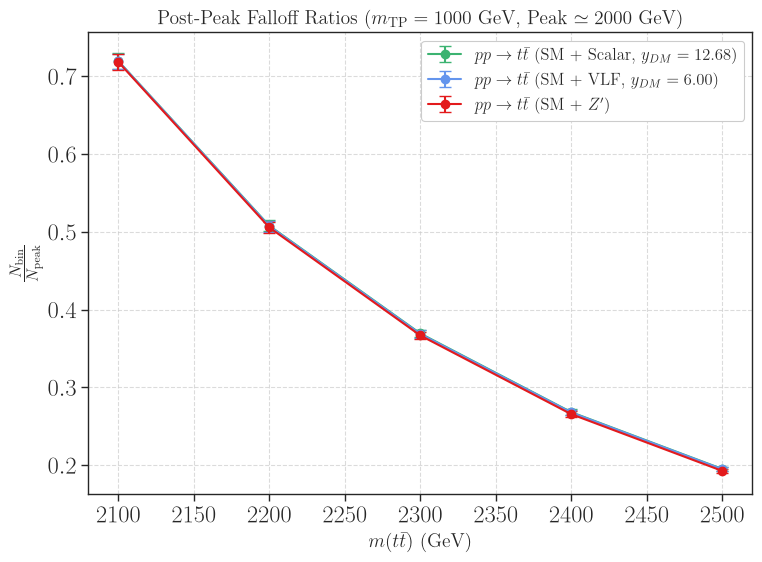

In [27]:
mTP = 1000.0 #GeV
peak = 2.0*mTP
bins = np.arange(450., 5500., 100.)
b_peak = 0
i=0
#Finding the bin where the peak is 
while (peak > bins[i] and i<=len(bins)):
    b_peak = i
    i+=1
ratios = []
ratios_err = []
#Computing the ratios
for i, h in enumerate(bsm_hists):
    aux = []
    err = []
    for j in range(b_peak + 1, b_peak + 6):
        aux.append(h[j]/h[b_peak])
        #propagasting the error through the ratio
        err.append(abs(h[j]/h[b_peak]*np.sqrt((bsm_histsErr[i][j]/h[j])**2 + (bsm_histsErr[i][b_peak]/h[b_peak])**2)))
    ratios.append(aux)
    ratios_err.append(err)
#Plotting the ratios for each models
# ==========================================
# Plotting the ratios for each model
# ==========================================

# Calculate the bin centers for the x-axis
x_centers = [(bins[j] + bins[j+1]) / 2.0 for j in range(b_peak + 1, b_peak + 6)]

fig, ax = plt.subplots(figsize=(8, 6))

# Loop over the calculated ratios to plot them
for k in range(len(ratios)):
    # Assuming 'bsm_labels' and 'bsm_colors' are defined in your broader script
    # If not, it safely falls back to generic labels
    label = bsm_labels[k] if 'bsm_labels' in locals() else f"Model {k+1}"
    color = bsm_colors[k] if 'bsm_colors' in locals() else None
    
    ax.errorbar(x_centers, ratios[k], yerr=ratios_err[k], fmt='o-', 
                capsize=4, label=label, color=color, markersize=6, linewidth=1.5)

# Formatting the plot to match the style of your previous physics plots
ax.set_xlabel(r'$m(t\bar{t})$ (GeV)', fontsize=14)
ax.set_ylabel(r'$\frac{N_{\mathrm{bin}}}{N_{\mathrm{peak}}}$', fontsize=16)
ax.set_title(r'Post-Peak Falloff Ratios ($m_{\mathrm{TP}} = 1000$ GeV, Peak $\simeq 2000$ GeV)', fontsize=14)

ax.grid(True, linestyle='--', alpha=0.7)
ax.legend(fontsize=12, framealpha=1.0)

# Optional: Set y-scale to logarithmic if the falloff is very steep
# ax.set_yscale('log')

plt.tight_layout()
#plt.savefig('Post_Peak_Ratios.png', dpi=300)
plt.show()
    

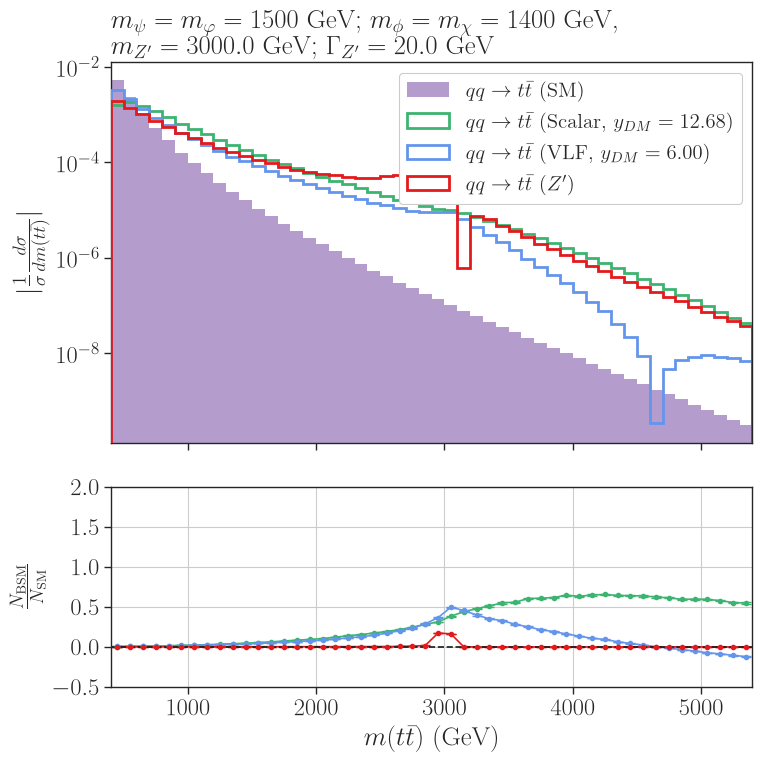

In [28]:


# Loop over the masses configurations. Each mass configuration has 4 items (2 models x 2 processes: qq, gg)
for i in range(0, len(data_NLO), 4):
    selected = data_NLO[i : i+4]

    # BSM masses and couplings
    mPsiT, mSDM = selected[0]['mass_params']
    yDM = selected[0]['ydm']
    
    # --- Setup and Binning ---
    fig, axarr = plt.subplots(2, sharex=True, gridspec_kw={'height_ratios': [1.9, 1]}, figsize=(8, 8))
    plt.subplots_adjust(left=0.12, bottom=0.12, right=0.97, top=None, wspace=None, hspace=0.1)

    if mPsiT < 600:
        bins = np.arange(400., 3000., 50.)
    elif mPsiT < 1000:
        bins = np.arange(500., 4000., 75.)
    else:
        bins = np.arange(400., 5500., 100.)
        
    x = (bins[:-1] + bins[1:]) / 2.0  
    bin_widths = np.diff(bins)

    ##############
    #  Main Plot #
    ##############
    
    pmodels = []
    labels_sm = []
    bsm_hists, bsm_errs, bsm_labels, bsm_colors = [], [], [], []

    # ==========================================
    #  Plotting the SM (ONLY qq)
    # ==========================================
    h_sm_total = np.zeros(len(bins)-1)
    hErr_sm_total_sq = np.zeros(len(bins)-1)
    
    for d in data_qq_sm_exp:
        # Safely extract process string
        proc_str = str(np.atleast_1d(d['process'])[0]).lower()
        
        # SKIP gg contributions
        if 'q' not in proc_str:
            continue
            
        h, _ = np.histogram(d['mTT'], bins=bins, weights=d['weights'])
        hErr_sq, _ = np.histogram(d['mTT'], bins=bins, weights=np.array(d['weights'])**2)
        h_sm_total += h
        hErr_sm_total_sq += hErr_sq
    
    process = r'$q q \to t \bar{t}$'  # Updated Label
    model = 'SM'
    pmodels.append(r'%s (%s)' % (process, model))
    label_sm = pmodels[-1]
    labels_sm.append(label_sm)
        
    integral_sm = np.sum(h_sm_total)
    h_sm = h_sm_total #/ (integral_sm * bin_widths) if integral_sm > 0 else h_sm_total
    hErr_sm = np.sqrt(hErr_sm_total_sq) #/ (integral_sm * bin_widths) if integral_sm > 0 else np.sqrt(hErr_sm_total_sq)
    
    axarr[0].hist(bins[:-1], weights=np.abs(h_sm), label=label_sm, bins=bins, density=True,
                  color=sns.color_palette('Paired')[9], alpha=0.5, histtype='step', 
                  linewidth=0, fill=True, zorder=0)

    # ==========================================
    #  Plotting the NLO BSM Data (ONLY qq)
    # ==========================================
    y_DM = {'1-loop VLF': 6.0, '1-loop Scalar': 1.268000e+01}
    for d in selected:
        # Safely extract process string
        proc_str = str(np.atleast_1d(d['process'])[0]).lower()
        
        # SKIP gg contributions
        if 'q' not in proc_str:
            continue
            
        process = r'$q q \to t \bar{t}$'  # Updated Label
        model_raw = d['model']
        model = d['model']
        model_raw = d['model']
        model_name = str(np.atleast_1d(model_raw)[0])
        display_name = model_name.replace('1-loop ', '')
        
        val_y_dm = y_DM.get(model_name, 1.0)
        

        display_name = model_name.replace('1-loop ', '')
        pmodels.append(r'%s (%s, $y_{DM} = %.2f$)' % (process, display_name, val_y_dm))
        label = pmodels[-1]
        
        color = get_color_by_mass(model, (mPsiT, mSDM))
        scale_weight = y_DM.get(model_name, 1.0)**2 
        
        # Calculate for qq only
        h_bsm_total, _ = np.histogram(d['mTT'], bins=bins, weights=d['weights'])
        hErr_bsm_total_sq, _ = np.histogram(d['mTT'], bins=bins, weights=np.array(d['weights'])**2)
        
        integral_bsm = np.sum(h_bsm_total)
        h_bsm = h_bsm_total * scale_weight #/ (integral_bsm * bin_widths) if integral_bsm > 0 else h_bsm_total
        hErr_bsm = np.sqrt(hErr_bsm_total_sq) * scale_weight #/ (integral_bsm * bin_widths) if integral_bsm > 0 else np.sqrt(hErr_bsm_total_sq)

        bsm_hists.append(h_bsm)
        bsm_errs.append(hErr_bsm)
        bsm_labels.append(label)
        bsm_colors.append(color)

        axarr[0].hist(bins[:-1], weights=np.abs(h_bsm), label=label, bins=bins,
                      color=color, alpha=1.0, histtype='step', density=True,
                      linewidth=2, fill=False, zorder=3)

    # ==========================================
    #  Plotting the Z' Data (ONLY qq)
    # ==========================================
    h_z_total = np.zeros(len(bins)-1)
    hErr_z_total_sq = np.zeros(len(bins)-1)
    model_z = ""
    
    for d in data_Z:
        # Safely extract process string
        proc_str = str(np.atleast_1d(d['process'])[0]).lower()
        
        
            
        h, _ = np.histogram(d['mTT'], bins=bins, weights=d['weights'])
        hErr_sq, _ = np.histogram(d['mTT'], bins=bins, weights=np.array(d['weights'])**2)
        h_z_total += h
        hErr_z_total_sq += hErr_sq
        model_z = str(np.atleast_1d(d['model'])[0])
        
    if len(data_Z) > 0 and integral_sm > 0: # Ensure we actually gathered qq data
        process = r'$q q \to t \bar{t}$' # Updated Label
        pmodels.append(r'%s (%s)' % (process, r'$Z^\prime$'))
        label_z = pmodels[-1]
        
        color_z = get_color_by_mass(model_z, (mPsiT, mSDM)) 
        
        integral_z = np.sum(h_z_total)
        h_z = h_z_total #/ (integral_z * bin_widths) if integral_z > 0 else h_z_total
        hErr_z = np.sqrt(hErr_z_total_sq) #/ (integral_z * bin_widths) if integral_z > 0 else np.sqrt(hErr_z_total_sq)
        
        bsm_hists.append(h_z)
        bsm_errs.append(hErr_z)
        bsm_labels.append(label_z)
        bsm_colors.append(color_z)
        
        axarr[0].hist(bins[:-1], weights=np.abs(h_z), label=label_z, bins=bins,
                      color=color_z, alpha=1.0, histtype='step', density=True,
                      linewidth=2, fill=False, zorder=3)


    ############
    #  SUBPLOT #
    ############
    with np.errstate(divide='ignore', invalid='ignore'):
        # Calculate the raw ratio first to properly calculate the relative error
        raw_ratio = np.nan_to_num(np.array(bsm_hists) / h_sm)
        
        ratio = raw_ratio 
        
        # Propagate the errors for the ratio 
        err_bsm_rel = np.nan_to_num(np.array(bsm_errs) / np.array(bsm_hists))
        err_sm_rel = np.nan_to_num(hErr_sm / h_sm)
        
        ratio_err = np.abs(raw_ratio) * np.sqrt(err_bsm_rel**2 + err_sm_rel**2)


    for k, r in enumerate(ratio):
        # Using errorbar for the ratio points to show the propagated MC uncertainty
        axarr[1].errorbar(x, r, yerr=ratio_err[k], color=bsm_colors[k], fmt='o', ms=3, capsize=3.5, label=bsm_labels[k])
        axarr[1].plot(x, r, color=bsm_colors[k]) # Add a line connecting points


    #################
    #  Plot configs #
    #################
    
    # Safely extract Z' properties
    mZp = data_Z[0].get('mZp', 0.0) if len(data_Z) > 0 else 0.0
    wZp = data_Z[0].get('wZp', 0.0) if len(data_Z) > 0 else 0.0

    # Upper plot
    axarr[0].legend(framealpha=1.0, ncol=1, loc='upper right', fontsize=15)
    axarr[0].set_title(
        (r'$m_{\psi} = m_{\varphi} = %1.0f$ GeV; $m_{\phi} = m_\chi = %1.0f$ GeV,' + '\n' +
         r'$m_{Z^\prime} = %1.1f$ GeV; $\Gamma_{Z^\prime} = %1.1f$ GeV') % 
        (mPsiT, mSDM, mZp, 20.0), 
        loc='left'
    )
    axarr[0].set_yscale('log')
    axarr[0].set_ylabel(r'$|\frac{1}{\sigma}\frac{d \sigma}{d m(t\bar{t})}|$')
    axarr[0].set_xlim(bins.min(), bins.max())


    # Bottom plot
    axarr[1].axhline(y=0, color='k', linestyle='--') # Baseline is now at 0
    axarr[1].set_ylabel(r'$\frac{N_{\mathrm{BSM}}}{ N_{\mathrm{SM}}}$') 
    axarr[1].set_xlabel(r'$m(t\bar{t})$ (GeV)')
    axarr[1].grid(True)
    #axarr[1].set_yscale('symlog', linthresh=0.01)
    
    #axarr[1].set_ylim([-0.02, 3.0]) 
    
    
    #axarr[1].set_yticks([-0.01, 0.0, 0.01, 0.1, 1.0])
    axarr[1].set_yticks(np.arange(-0.5,2.5, 0.5))
    
    minor_tick_locations = np.concatenate((
        np.arange(-0.1, -0.01, 0.01),   
        np.arange(-0.01, 0.01, 0.001),  
        np.arange(0.01, 0.1, 0.01),    
        np.arange(0.1, 1.0, 0.1),       
        np.arange(1.0, 10.0, 1.0)       
    )) 
    
    # (Ensure 'from matplotlib.ticker import FixedLocator' is at the top of your script)
    #axarr[1].yaxis.set_minor_locator(FixedLocator(minor_tick_locations))

    plt.tight_layout()
    plt.savefig('Dists_qq_comparison_interference.png')
    plt.show()

In [29]:
import numpy as np
import matplotlib.pyplot as plt

# ==========================================
# Helper Functions
# ==========================================
def compute_hist(data_list, bins, weight_factor=1.0, z_prime = False, var = 'mTT', sm = False):
    """Computes the histogram and its statistical error (sqrt of sum of squared weights)."""
    h_total = np.zeros(len(bins) - 1)
    hErr_sq_total = np.zeros(len(bins) - 1)
    
    for i,d in enumerate(data_list):
        if z_prime and i==1: weight_factor = np.sqrt(weight_factor)
        weights = np.array(d['weights']) * weight_factor
        h, _ = np.histogram(d[var], bins=bins, weights=weights)
        hErr_sq, _ = np.histogram(d[var], bins=bins, weights=weights**2)
        h_total += h
        hErr_sq_total += hErr_sq
    if sm:
        h_total = h_total/(i+1)
        hErr_sq_total = hErr_sq_total/(i+1)**2
        
    return h_total, np.sqrt(hErr_sq_total)

# ==========================================
# General Configuration
# ==========================================
colors = plt.cm.tab10.colors
color_map = {
    'SM': 'gray',
    'VLF': colors[2],
    'Scalar': colors[0],
    'Zprime': colors[3],
    'Zprime_20pc': 'cyan',
    'FakeData': 'black'
}
bin_dict = {'mTT':np.arange(300.,8100.,100.), 'pT': np.arange(0.0, 5100.0, 100.0),
           'cost*':np.arange(-1.0, 1.1, 0.1)}
xsec_dict = {'mTT':{}, 'pT':{},'cost*':{}}
y_DM_dict = {'1-loop VLF': 3.5, '1-loop Scalar': 7.5, 'Zprime': 0.26}

# ==========================================
# Main Processing Loop
# ==========================================
for i in range(0, len(data_NLO), 4):
    selected = data_NLO[i : i+4]

    # Extract Physics Parameters
    mPsiT, mSDM = selected[0]['mass_params']
    yDM = selected[0]['ydm']

 

    #bins = np.arange(000., 8100., 100.)
        
    #x_centers = (bins[:-1] + bins[1:]) / 2.0  
    
    # Storage for ratio plot
    bsm_hists, bsm_errs, bsm_labels = [], [], []

    # ------------------------------------------
    #  Process Standard Model (SM)
    # ------------------------------------------
    for v in bin_dict.keys():
        h_sm, hErr_sm = compute_hist(data_sm_exp, bin_dict[v], var = v, sm = True)
        h_sm_qq, _ = compute_hist(data_qq_sm_exp, bin_dict[v], var = v, sm = True)
        xsec_dict[v]['SM'] = np.sum(h_sm)
        xsec_dict[v]['SM_qq'] = np.sum(h_sm_qq)
        xsec_dict[v]['SM_gg'] = np.sum(h_sm) - np.sum(h_sm_qq)
    


    # ------------------------------------------
    #  Process NLO BSM Data (Summing qq + gg)
    # ------------------------------------------
    for j in range(0, len(selected), 2):
        d_qq = selected[j]
        d_gg = selected[j+1]
        
        # Format model names
        model_raw = d_qq['model']
        model_name = str(np.atleast_1d(model_raw)[0])
        display_name = model_name.replace('1-loop ', '')

        # Get Couplings and scale factor
        val_y_dm = y_DM_dict.get(model_name, 1.0)
        scale_weight = val_y_dm**2 

        for v in bin_dict.keys():
        # Calculate Histograms for qq and gg, then combine
            h_bsm_qq, _ = compute_hist([d_qq], bin_dict[v], weight_factor=scale_weight, var = v)
            h_bsm_gg, _ =compute_hist([d_gg], bin_dict[v], weight_factor=scale_weight, var = v)
            qq_name = display_name + '_qq'
            gg_name = display_name + '_gg'
            xsec_dict[v][qq_name] = np.sum(h_bsm_qq)
            xsec_dict[v][gg_name] = np.sum(h_bsm_gg)
            xsec_dict[v][display_name] = np.sum(h_bsm_qq) + np.sum(h_bsm_gg)
        

    # ------------------------------------------
    #  Process Z' 
    # ------------------------------------------
    if len(data_Z) > 0:
        for v in bin_dict.keys():
            h_z, hErr_z = compute_hist([data_Z[0]], bin_dict[v], weight_factor=y_DM_dict['Zprime']**2, var = v)
            h_z_int, _  = compute_hist([data_Z[1]], bin_dict[v], weight_factor=y_DM_dict['Zprime'], var = v)
            xsec_dict[v]['Zprime' + '_bsm_sq'] = np.sum(h_z)
            xsec_dict[v]['Zprime' + '_int'] = np.sum(h_z_int)
            xsec_dict[v]['Zprime'] = np.sum(h_z) + np.sum(h_z_int)
        
        
        

   
print(xsec_dict['cost*'])
print(xsec_dict['mTT'])

{'SM': np.float64(522.8723396421689), 'SM_qq': np.float64(64.21385222010694), 'SM_gg': np.float64(458.6584874220619), 'Scalar_qq': np.float64(0.0648000000000735), 'Scalar_gg': np.float64(-0.50422499936877), 'Scalar': np.float64(-0.4394249993686965), 'VLF_qq': np.float64(0.10209150000920188), 'VLF_gg': np.float64(0.11450074805898543), 'VLF': np.float64(0.2165922480681873), 'Zprime_bsm_sq': np.float64(5.6977699771162545e-05), 'Zprime_int': np.float64(5.336120335584921e-05), 'Zprime': np.float64(0.00011033890312701176)}
{'SM': np.float64(522.8723405950276), 'SM_qq': np.float64(64.2138522032133), 'SM_gg': np.float64(458.6584883918143), 'Scalar_qq': np.float64(0.06480000085733892), 'Scalar_gg': np.float64(-0.5042249999304255), 'Scalar': np.float64(-0.4394249990730865), 'VLF_qq': np.float64(0.10209150291904083), 'VLF_gg': np.float64(0.1145007500150755), 'VLF': np.float64(0.21659225293411632), 'Zprime_bsm_sq': np.float64(5.697770302014801e-05), 'Zprime_int': np.float64(5.336120262525129e-05),

| Process / Model   |           mTT |            pT |         cost* |
|:------------------|--------------:|--------------:|--------------:|
| SM                | 522.872       | 522.872       | 522.872       |
| SM_qq             |  64.2139      |  64.2139      |  64.2139      |
| SM_gg             | 458.658       | 458.658       | 458.658       |
| Scalar_qq         |   0.0648      |   0.0648      |   0.0648      |
| Scalar_gg         |  -0.504225    |  -0.504225    |  -0.504225    |
| Scalar            |  -0.439425    |  -0.439425    |  -0.439425    |
| VLF_qq            |   0.102092    |   0.102092    |   0.102092    |
| VLF_gg            |   0.114501    |   0.114501    |   0.114501    |
| VLF               |   0.216592    |   0.216592    |   0.216592    |
| Zprime_bsm_sq     |   5.69777e-05 |   5.69777e-05 |   5.69777e-05 |
| Zprime_int        |   5.33612e-05 |   5.33612e-05 |   5.33612e-05 |
| Zprime            |   0.000110339 |   0.000110339 |   0.000110339 |


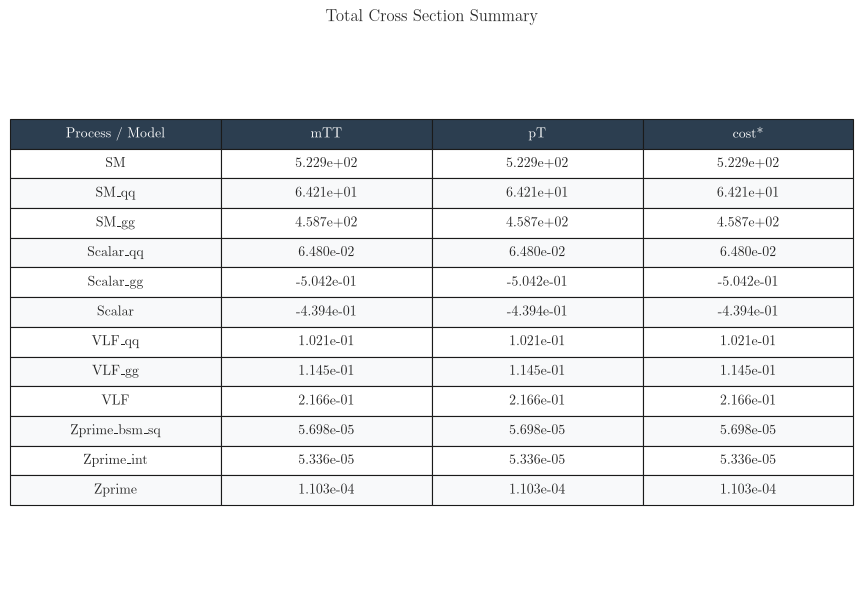

In [30]:
import matplotlib.pyplot as plt
import pandas as pd

# 1. Convert xsec_dict to a structured DataFrame
df_xsec = pd.DataFrame(xsec_dict)
df_xsec.index.name = 'Process / Model'

# Print Markdown table directly to console / notebook
print(df_xsec.to_markdown())

# 2. Plot the DataFrame as a Matplotlib Table Figure
fig, ax = plt.subplots(figsize=(9, len(df_xsec) * 0.4 + 1.5))
ax.axis('off')

# Format cross-section numbers into scientific notation for readability
cell_text = []
for row in df_xsec.itertuples():
    formatted_row = [row[0]] + [f"{val:.3e}" if isinstance(val, (int, float)) else str(val) for val in row[1:]]
    cell_text.append(formatted_row)

headers = ['Process / Model'] + list(df_xsec.columns)

table = ax.table(
    cellText=cell_text,
    colLabels=headers,
    loc='center',
    cellLoc='center'
)

# Styling
table.auto_set_font_size(False)
table.set_fontsize(10)
table.scale(1.2, 1.6)

# Header formatting and alternating row colors
for (r, c), cell in table.get_celld().items():
    if r == 0:
        cell.set_facecolor('#2c3e50')
        cell.set_text_props(color='white', weight='bold')
    else:
        cell.set_facecolor('#f8f9fa' if r % 2 == 0 else '#ffffff')

plt.title('Total Cross Section Summary', fontsize=12, pad=15, weight='bold')
plt.tight_layout()
plt.savefig('cross_sections_table.png', dpi=300, bbox_inches='tight')
plt.show()

In [15]:


files =( list(glob.glob(
        '/home/vinicius/EFT_ToyModel/processFolders/'
        'Distributions_13_6TeV/bias/z_prime/*/'
        'mass_scan_1pc*/*2900*.npz'
    ))
      #+list(glob.glob('/home/vinicius/EFT_ToyModel/processFolders/Distributions/bias/z_prime/pp2ttbar_dmv2_qed2/*3000*.npz'))
       )
print(files)
#files = list(glob.glob('/home/vinicius/EFT_ToyModel/test/Distributions/*/*/*.npz'))
data_Z_1 = []
#data_sm = []
#Loading the distributions
for f in files:
    aux = np.load(f, allow_pickle = True)
    data_Z_1.append(aux)

data_Z_1 = sorted(data_Z_1, key=lambda d: d['mZp'])

['/home/vinicius/EFT_ToyModel/processFolders/Distributions_13_6TeV/bias/z_prime/pp2ttbar_dmv2_qed2/mass_scan_1pc_width_int/mZp_2900.npz', '/home/vinicius/EFT_ToyModel/processFolders/Distributions_13_6TeV/bias/z_prime/pp2ttbar_dmv4/mass_scan_1pc_width/mZp_2900.npz']


In [16]:
files =( list(glob.glob(
        '/home/vinicius/EFT_ToyModel/processFolders/'
        'Distributions_13_6TeV/bias/z_prime/*/'
        'mass_scan_1pc*/*2500*.npz'
    ))
      #+list(glob.glob('/home/vinicius/EFT_ToyModel/processFolders/Distributions/bias/z_prime/pp2ttbar_dmv2_qed2/*3000*.npz'))
       )
print(files)
#files = list(glob.glob('/home/vinicius/EFT_ToyModel/test/Distributions/*/*/*.npz'))
data_Z_2 = []
#data_sm = []
#Loading the distributions
for f in files:
    aux = np.load(f, allow_pickle = True)
    data_Z_2.append(aux)

data_Z_2 = sorted(data_Z_2, key=lambda d: d['mZp'])

['/home/vinicius/EFT_ToyModel/processFolders/Distributions_13_6TeV/bias/z_prime/pp2ttbar_dmv2_qed2/mass_scan_1pc_width_int/mZp_2500.npz', '/home/vinicius/EFT_ToyModel/processFolders/Distributions_13_6TeV/bias/z_prime/pp2ttbar_dmv4/mass_scan_1pc_width/mZp_2500.npz']


1-loop Scalar 0.00821449761501359
1-loop VLF 0.01057171573438867


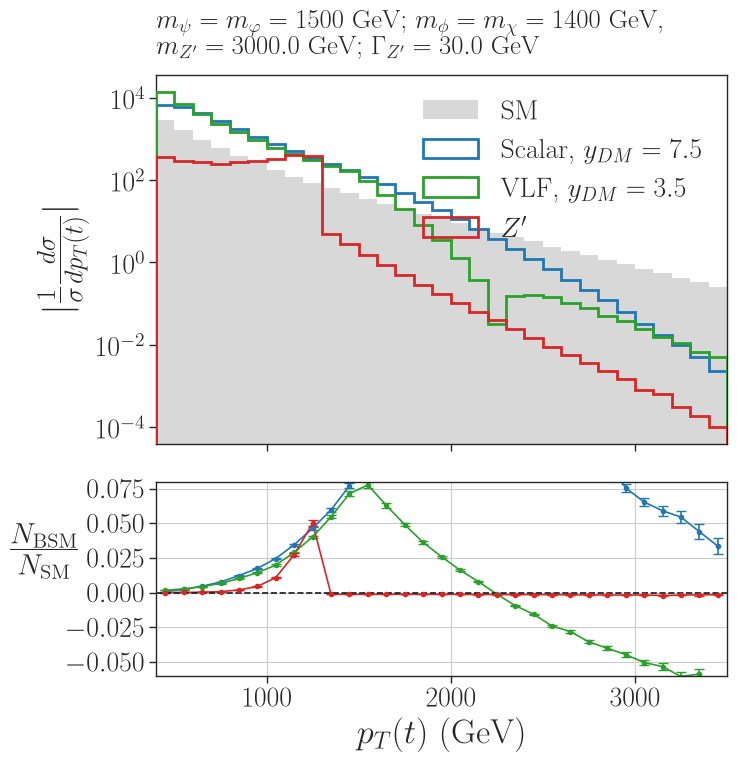

In [17]:
import numpy as np
import matplotlib.pyplot as plt

lumi = 3000 *1000

# ==========================================
# Helper Functions
# ==========================================
def compute_hist(data_list, bins, var='pT', weight_factor=1.0, z_prime=False):
    """Computes the histogram and its statistical error (sqrt of sum of squared weights) for a given variable."""
    h_total = np.zeros(len(bins) - 1)
    hErr_sq_total = np.zeros(len(bins) - 1)
    
    for i, d in enumerate(data_list):
        current_weight_factor = weight_factor
        if z_prime and i == 0: 
            current_weight_factor = -np.sqrt(weight_factor)
            
        weights = np.array(d['weights']) * current_weight_factor
        h, _ = np.histogram(d[var], bins=bins, weights=weights)
        hErr_sq, _ = np.histogram(d[var], bins=bins, weights=weights**2)
        
        h_total += h
        hErr_sq_total += hErr_sq
        
    return h_total, np.sqrt(hErr_sq_total)

# ==========================================
# General Configuration
# ==========================================
colors = plt.cm.tab10.colors
color_map = {
    'SM': 'gray',
    'VLF': colors[2],
    'Scalar': colors[0],
    'Zprime': colors[3],
    'Zprime_20pc': 'cyan',
    'FakeData': 'black'
}

# Variable to plot
var = 'pT'

# Couplings for pT
y_DM_dict = {'1-loop VLF': 3.5, '1-loop Scalar': 7.5}

# ==========================================
# Main Processing Loop
# ==========================================
for i in range(0, len(data_NLO), 4):
    selected = data_NLO[i : i+4]

    # Extract Physics Parameters
    mPsiT, mSDM = selected[0]['mass_params']
    yDM = selected[0]['ydm']
    
    # ------------------------------------------
    # 1. Setup and Binning (pT Specific)
    # ------------------------------------------
    fig, axarr = plt.subplots(2, sharex=True, gridspec_kw={'height_ratios': [1.9, 1]}, figsize=(8, 8))
    plt.subplots_adjust(left=0.12, bottom=0.12, right=0.97, hspace=0.1)

    if mPsiT < 600:
        bins = np.arange(400., 3000., 50.)
    elif mPsiT < 1000:
        bins = np.arange(500., 4000., 75.)
    else:
        bins = np.arange(400., 3600., 100.)
        
    x_centers = (bins[:-1] + bins[1:]) / 2.0  
    
    # Storage for ratio plot
    bsm_hists, bsm_errs, bsm_labels = [], [], []

    # ------------------------------------------
    # 2. Process Standard Model (SM)
    # ------------------------------------------
    h_sm, hErr_sm = compute_hist(data_sm_exp, bins, var=var)
    
    axarr[0].hist(bins[:-1], weights=np.sqrt(np.abs(lumi*h_sm)), bins=bins, density=False,
                  color=color_map['SM'], alpha=0.3, histtype='step', 
                  linewidth=0.0, fill=True, zorder=0, label='SM')

    # ------------------------------------------
    # 3. Process NLO BSM Data (Summing qq + gg)
    # ------------------------------------------
    for j in range(0, len(selected), 2):
        d_qq = selected[j]
        d_gg = selected[j+1]
        
        # Format model names
        model_raw = d_qq['model']
        model_name = str(np.atleast_1d(model_raw)[0])
        display_name = model_name.replace('1-loop ', '')
        
        # Get Couplings and scale factor
        val_y_dm = y_DM_dict.get(model_name, 1.0)
        scale_weight = val_y_dm**2 
        
        # Calculate Histograms for qq and gg, then combine
        h_bsm, hErr_bsm = compute_hist([d_qq, d_gg], bins, var=var, weight_factor=scale_weight)

        # Store for ratio plot
        bsm_hists.append(h_bsm)
        bsm_errs.append(hErr_bsm)
        bsm_labels.append(display_name)
        print(model_name, np.sum(h_bsm))
        
        # Plot Upper Panel
        label_str = rf'{display_name}, $y_{{DM}} = {val_y_dm:.1f}$'
        axarr[0].hist(bins[:-1], weights=np.abs(lumi*h_bsm), bins=bins, density=False,
                      color=color_map[display_name], alpha=1.0, histtype='step', 
                      linewidth=2, fill=False, zorder=3, label=label_str)

    # ------------------------------------------
    # 4. Process Z' 
    # ------------------------------------------
    if len(data_Z_2) > 0:
        h_z, hErr_z = compute_hist(data_Z_2, bins, var=var, weight_factor=(0.28**2), z_prime=True)
        
        bsm_hists.append(h_z)
        bsm_errs.append(hErr_z)
        bsm_labels.append('Zprime')
        
        axarr[0].hist(bins[:-1], weights=np.abs(lumi*h_z), bins=bins, density=False,
                      color=color_map['Zprime'], alpha=1.0, histtype='step', 
                      linewidth=2, fill=False, zorder=3, label=r'$Z^\prime$')

    # ------------------------------------------
    # 5. Process Ratio (Subplot)
    # ------------------------------------------
    with np.errstate(divide='ignore', invalid='ignore'):
        raw_ratio = np.nan_to_num(np.array(bsm_hists) / h_sm)
        
        # Propagate errors for the ratio (sigma_R / R = sqrt((sigma_A/A)^2 + (sigma_B/B)^2))
        err_bsm_rel = np.nan_to_num(np.array(bsm_errs) / np.array(bsm_hists))
        err_sm_rel = np.nan_to_num(hErr_sm / h_sm)
        ratio_err = np.abs(raw_ratio) * np.sqrt(err_bsm_rel**2 + err_sm_rel**2)

    for k, r in enumerate(raw_ratio):
        plot_color = color_map[bsm_labels[k]]
        axarr[1].errorbar(x_centers, r, yerr=ratio_err[k], color=plot_color, 
                          fmt='o', ms=3, capsize=3.5, label=bsm_labels[k])
        axarr[1].plot(x_centers, r, color=plot_color)

    # ------------------------------------------
    # 6. Plot Formatting & Beautification
    # ------------------------------------------
    
    # Upper Plot Config
    mZp = data_Z[0].get('mZp', 0.0) if len(data_Z) > 0 else 0.0
    wZp = data_Z[0].get('wZp', 30.0) if len(data_Z) > 0 else 30.0
    
    title_str = (rf'$m_{{\psi}} = m_{{\varphi}} = {mPsiT:.0f}$ GeV; '
                 rf'$m_{{\phi}} = m_\chi = {mSDM:.0f}$ GeV,' + '\n' +
                 rf'$m_{{Z^\prime}} = {mZp:.1f}$ GeV; $\Gamma_{{Z^\prime}} = {wZp:.1f}$ GeV')
    
    axarr[0].set_title(title_str, loc='left', pad=15)
    axarr[0].legend(framealpha=0.0, ncol=1, loc='upper right', fontsize=20)
    axarr[0].set_yscale('log')
    axarr[0].set_ylabel(r'$|\frac{1}{\sigma}\frac{d \sigma}{d p_T(t)}|$', fontsize=27)
    axarr[0].set_xlim(bins.min(), bins.max())
    #axarr[0].set_ylim(1e-13, 2e+3)
    axarr[0].tick_params(axis='both', width=1, labelsize=20)


    # Bottom Plot Config
    axarr[1].axhline(y=0, color='k', linestyle='--')
    axarr[1].set_ylabel(r'$\frac{N_{\mathrm{BSM}}}{ N_{\mathrm{SM}}}$', fontsize=30, rotation=0, labelpad=15) 
    axarr[1].set_xlabel(r'$p_T(t)$ (GeV)', fontsize=25)
    axarr[1].set_ylim([-0.06, 0.08]) # Bounding strictly around the yticks
    axarr[1].set_yticks(np.arange(-0.05, 0.08, 0.025))
    axarr[1].grid(True)
    axarr[1].tick_params(axis='both', width=1, labelsize=20)

    # Save and Show
    plt.tight_layout()
    #plt.savefig('Dists_comparison_pT.png')
    plt.show()

In [18]:
files =( list(glob.glob(
        '/home/vinicius/EFT_ToyModel/processFolders/'
        'Distributions_13_6TeV/bias/z_prime/*/'
        'mass_scan_1pc*/*2400*.npz'
    ))
      #+list(glob.glob('/home/vinicius/EFT_ToyModel/processFolders/Distributions/bias/z_prime/pp2ttbar_dmv2_qed2/*3000*.npz'))
       )
print(files)
#files = list(glob.glob('/home/vinicius/EFT_ToyModel/test/Distributions/*/*/*.npz'))
data_Z_3 = []
#data_sm = []
#Loading the distributions
for f in files:
    aux = np.load(f, allow_pickle = True)
    data_Z_3.append(aux)

data_Z_3 = sorted(data_Z_3, key=lambda d: d['mZp'])

['/home/vinicius/EFT_ToyModel/processFolders/Distributions_13_6TeV/bias/z_prime/pp2ttbar_dmv2_qed2/mass_scan_1pc_width_int/mZp_2400.npz', '/home/vinicius/EFT_ToyModel/processFolders/Distributions_13_6TeV/bias/z_prime/pp2ttbar_dmv4/mass_scan_1pc_width/mZp_2400.npz']



Zprime_1
  coupling scale = 0.39990956
  weight factor  = 0.15992766
  minimum        = 24.536247

Zprime_2
  coupling scale = 0.33523579
  weight factor  = 0.11238304
  minimum        = 24.042607

Zprime_3
  coupling scale = 0.30370129
  weight factor  = 0.092234474
  minimum        = 26.383372


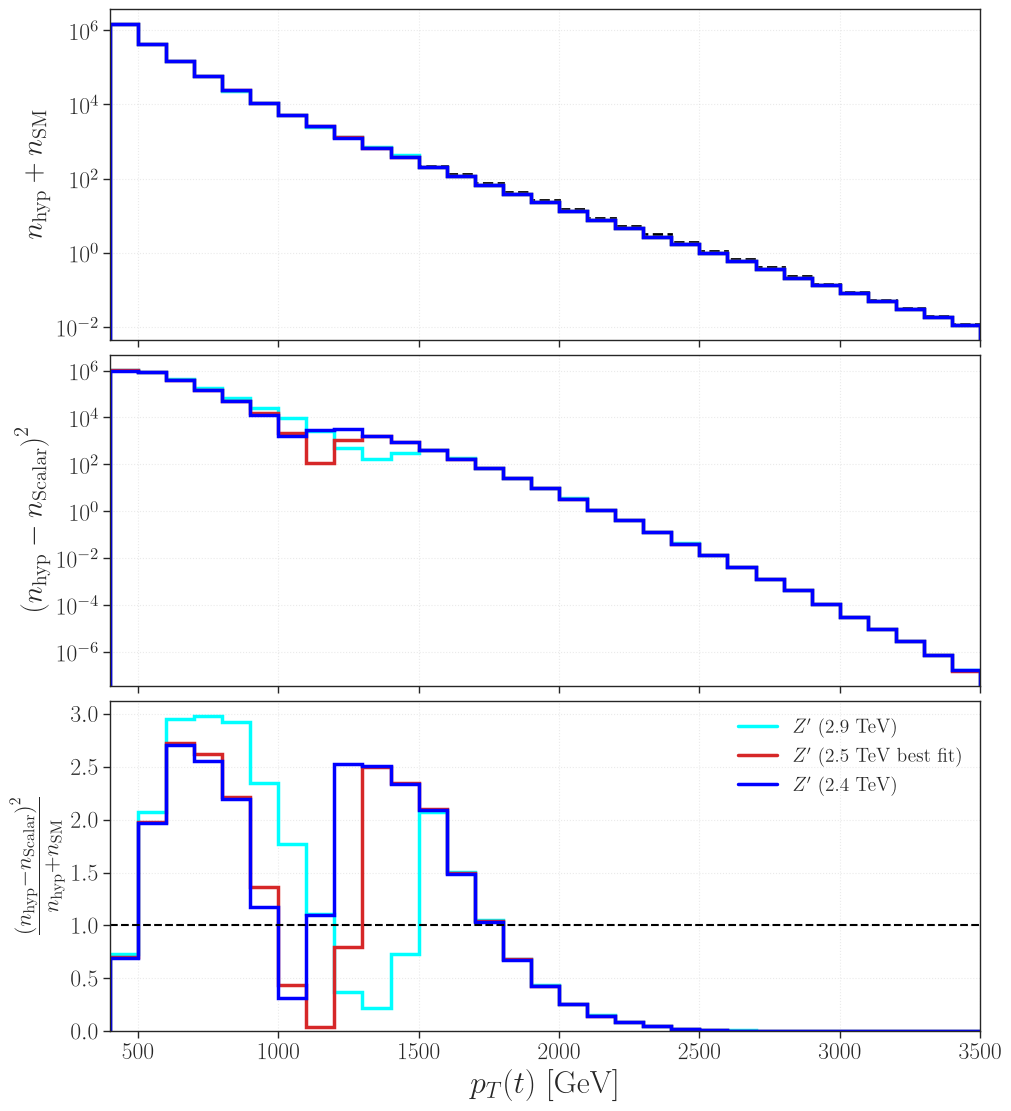

In [23]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import minimize_scalar


# ============================================================
# Configuration
# ============================================================

LUMI_FB = 500.0
lum = LUMI_FB * 1000.0

var = "pT"
PT_ANALYSIS_RANGE = (400.0, 3500.0)
WEIGHT_BOUNDS = (0.0, 5.0)

y_DM_dict = {
    "1-loop VLF": 3.5,
    "1-loop Scalar": 7.5,
}

colors = plt.cm.tab10.colors

color_map = {
    "Zprime_1": "cyan",
    "Zprime_2": colors[3],
    "Zprime_3": "blue",
}

zprime_labels = {
    "Zprime_1": r"$Z^\prime$ (2.9 TeV)",
    "Zprime_2": r"$Z^\prime$ (2.5 TeV best fit)",
    "Zprime_3": r"$Z^\prime$ (2.4 TeV)",
}


# ============================================================
# Generic histogram
# ============================================================

def compute_hist(data_list, bins, var="pT", weight_factor=1.0):
    h_total = np.zeros(len(bins) - 1, dtype=float)

    for data in data_list:
        x = np.asarray(data[var], dtype=float)
        weights = np.asarray(data["weights"], dtype=float) * weight_factor

        h, _ = np.histogram(x, bins=bins, weights=weights)
        h_total += h

    return h_total


# ============================================================
# Z' histogram preparation
# ============================================================

def prepare_zprime_histograms(data_z, bins, var="pT"):
    """
    Convention:
        data_z[0]  = interference contribution
        data_z[1:] = pure Z' contribution(s)

    The fitted histogram is

        h_Z'(w) = -sqrt(w) h_int + w h_pure.
    """
    if len(data_z) < 2:
        raise ValueError(
            "Z' data must contain at least one interference "
            "sample and one pure contribution."
        )

    h_int = compute_hist([data_z[0]], bins, var=var)
    h_pure = compute_hist(data_z[1:], bins, var=var)

    return h_int, h_pure


def build_zprime_hist(weight_factor, h_int, h_pure):
    return -np.sqrt(weight_factor) * h_int + weight_factor * h_pure


# ============================================================
# Function to minimize
# ============================================================

def zprime_objective_fast(
    weight_factor,
    h_int,
    h_pure,
    n_scalar,
    n_sm,
    lum,
    fit_mask,
):
    """
    Minimize

        sum_i (n_Z' - n_Scalar)^2 / (n_Z' + n_SM)
    """
    if weight_factor < 0.0:
        return np.inf

    h_z = build_zprime_hist(weight_factor, h_int, h_pure)
    n_z = lum * h_z

    denominator = n_z + n_sm
    denominator_fit = denominator[fit_mask]

    if (
        np.any(~np.isfinite(denominator_fit))
        or np.any(denominator_fit <= 0.0)
    ):
        return np.inf

    diff = n_z[fit_mask] - n_scalar[fit_mask]

    return float(np.sum(diff**2 / denominator_fit))


# ============================================================
# Fast Z' fit
# ============================================================

def fit_zprime_fast(
    data_z,
    bins,
    n_scalar,
    n_sm,
    lum,
    fit_mask,
    var="pT",
    weight_bounds=(0.0, 5.0),
):
    h_int, h_pure = prepare_zprime_histograms(
        data_z,
        bins,
        var=var,
    )

    result = minimize_scalar(
        zprime_objective_fast,
        bounds=weight_bounds,
        method="bounded",
        args=(
            h_int,
            h_pure,
            n_scalar,
            n_sm,
            lum,
            fit_mask,
        ),
        options={"xatol": 1e-8},
    )

    best_weight = result.x
    h_best = build_zprime_hist(best_weight, h_int, h_pure)

    n_best = lum * h_best

    denominator = n_best + n_sm
    numerator = (n_best - n_scalar)**2

    ratio = np.full(len(h_best), np.nan, dtype=float)

    valid = (
        fit_mask
        & np.isfinite(numerator)
        & np.isfinite(denominator)
        & (denominator > 0.0)
    )

    ratio[valid] = numerator[valid] / denominator[valid]

    return {
        "weight_factor": best_weight,
        "coupling_scale": np.sqrt(best_weight),
        "objective": result.fun,
        "hist": h_best,
        "numerator": numerator,
        "denominator": denominator,
        "ratio": ratio,
        "h_int": h_int,
        "h_pure": h_pure,
        "success": result.success,
    }


# ============================================================
# Main loop
# ============================================================

for i in range(0, len(data_NLO), 4):

    selected = data_NLO[i:i + 4]

    if len(selected) < 4:
        continue

    mPsiT, mSDM = selected[0]["mass_params"]

    # --------------------------------------------------------
    # Binning
    # --------------------------------------------------------

    if mPsiT < 600:
        bins = np.arange(400.0, 3000.0, 50.0)

    elif mPsiT < 1000:
        bins = np.arange(500.0, 4000.0, 75.0)

    else:
        bins = np.arange(400.0, 3600.0, 100.0)

    fit_mask = (
        (bins[:-1] >= PT_ANALYSIS_RANGE[0])
        & (bins[1:] <= PT_ANALYSIS_RANGE[1])
    )

    if not np.any(fit_mask):
        raise RuntimeError(
            "No bins lie inside the selected analysis range."
        )

    # ========================================================
    # SM
    # ========================================================

    h_sm = compute_hist(
        data_sm_exp,
        bins,
        var=var,
    )

    n_sm = lum * h_sm

    # ========================================================
    # Scalar reference
    # ========================================================

    bsm_hists = {}

    for j in range(0, len(selected), 2):

        d_qq = selected[j]
        d_gg = selected[j + 1]

        model_name = str(
            np.atleast_1d(d_qq["model"])[0]
        )

        display_name = model_name.replace(
            "1-loop ",
            "",
        )

        # Only Scalar is needed as the reference
        if display_name == "VLF":
            continue

        y_dm = y_DM_dict.get(
            model_name,
            1.0,
        )

        h_bsm = compute_hist(
            [d_qq, d_gg],
            bins,
            var=var,
            weight_factor=y_dm**2,
        )

        bsm_hists[display_name] = h_bsm

    if "Scalar" not in bsm_hists:
        raise RuntimeError(
            "Scalar histogram not found."
        )

    h_scalar = bsm_hists["Scalar"]
    n_scalar = lum * h_scalar

    # ========================================================
    # Fit the three Z' hypotheses
    # ========================================================

    zprime_datasets = {
        "Zprime_1": data_Z_1,
        "Zprime_2": data_Z_2,
        "Zprime_3": data_Z_3,
    }

    zprime_results = {}

    for key, data_z in zprime_datasets.items():

        if len(data_z) == 0:
            continue

        result = fit_zprime_fast(
            data_z=data_z,
            bins=bins,
            n_scalar=n_scalar,
            n_sm=n_sm,
            lum=lum,
            fit_mask=fit_mask,
            var=var,
            weight_bounds=WEIGHT_BOUNDS,
        )

        zprime_results[key] = result

        print(f"\n{key}")
        print(f"  coupling scale = {result['coupling_scale']:.8g}")
        print(f"  weight factor  = {result['weight_factor']:.8g}")
        print(f"  minimum        = {result['objective']:.8g}")

    # ========================================================
    # Three-panel figure
    # ========================================================

    fig, ax = plt.subplots(
        3,
        1,
        figsize=(10, 11),
        sharex=True,
        constrained_layout=True,
    )

    # --------------------------------------------------------
    # Scalar total expectation for comparison in panel 1
    # --------------------------------------------------------

    scalar_total = n_sm + n_scalar

    scalar_total_plot = np.full_like(
        scalar_total,
        np.nan,
        dtype=float,
    )

    valid_scalar_total = (
        fit_mask
        & np.isfinite(scalar_total)
        & (scalar_total > 0.0)
    )

    scalar_total_plot[
        valid_scalar_total
    ] = scalar_total[
        valid_scalar_total
    ]

    ax[0].stairs(
        scalar_total_plot,
        bins,
        color="black",
        linestyle="--",
        linewidth=2.0,
        label="Scalar",
    )

    # ========================================================
    # Z' curves
    # ========================================================

    for key, result in zprime_results.items():

        color = color_map[key]
        label = zprime_labels[key]

        denominator = result["denominator"].copy()
        numerator = result["numerator"].copy()
        ratio = result["ratio"].copy()

        # Restrict to fit region
        denominator[~fit_mask] = np.nan
        numerator[~fit_mask] = np.nan
        ratio[~fit_mask] = np.nan

        # Required for logarithmic y scales
        denominator[
            (~np.isfinite(denominator))
            | (denominator <= 0.0)
        ] = np.nan

        numerator[
            (~np.isfinite(numerator))
            | (numerator <= 0.0)
        ] = np.nan

        # ----------------------------------------------------
        # Panel 1:
        # n_hyp + n_SM
        # ----------------------------------------------------

        ax[0].stairs(
            denominator,
            bins,
            color=color,
            linewidth=2.5,
            label=label,
        )

        # ----------------------------------------------------
        # Panel 2:
        # (n_hyp - n_Scalar)^2
        # ----------------------------------------------------

        ax[1].stairs(
            numerator,
            bins,
            color=color,
            linewidth=2.5,
            label=label,
        )

        # ----------------------------------------------------
        # Panel 3:
        # (n_hyp - n_Scalar)^2 / (n_hyp + n_SM)
        # ----------------------------------------------------

        ax[2].stairs(
            ratio,
            bins,
            color=color,
            linewidth=2.5,
            label=label,
        )

    # ========================================================
    # Formatting
    # ========================================================

    # First panel
    ax[0].set_ylabel(
        r"$n_{\rm hyp}+n_{\rm SM}$",
        fontsize=21,
    )

    ax[0].set_yscale("log")

    ax[2].legend(
        frameon=False,
        fontsize=14,
    )

    # Second panel
    ax[1].set_ylabel(
        r"$\left(n_{\rm hyp}-n_{\rm Scalar}\right)^2$",
        fontsize=21,
    )

    ax[1].set_yscale("log")

    # Third panel
    ax[2].set_ylabel(
        r"$\frac{\left(n_{\rm hyp}-n_{\rm Scalar}\right)^2}"
        r"{n_{\rm hyp}+n_{\rm SM}}$",
        fontsize=23,
    )

    ax[2].set_xlabel(
        r"$p_T(t)$ [GeV]",
        fontsize=23,
    )

    ax[2].axhline(
        1.0,
        color="black",
        linestyle="--",
        linewidth=1.5,
    )

    # Common formatting
    for a in ax:
        a.set_xlim(PT_ANALYSIS_RANGE)
        a.grid(True, linestyle=":", alpha=0.4)
        a.tick_params(axis="both", labelsize=17, width=1)

    plt.show()

In [20]:
print('xsec (pb):',1.7479738e-03  + 8.2332386e-03  )
print('err (pb):', np.sqrt( 4.1344018e-07**2 + 3.0220481e-05**2))

xsec (pb): 0.0099812124
err (pb): 3.0223308962683083e-05


Scalar benchmark: ('Scalar', 1500.0, 1400.0)
Scalar samples: 2

Available VLF masses:
  1600, 1500 GeV: 2 samples
  1700, 1600 GeV: 2 samples
  1800, 1700 GeV: 2 samples
VLF m = 1600 GeV, mDM = 1500 GeV | best yDM = 3.673824 | Q = 1.670512
VLF m = 1700 GeV, mDM = 1600 GeV | best yDM = 3.969899 | Q = 1.549226
VLF m = 1800 GeV, mDM = 1700 GeV | best yDM = 4.257748 | Q = 1.624546


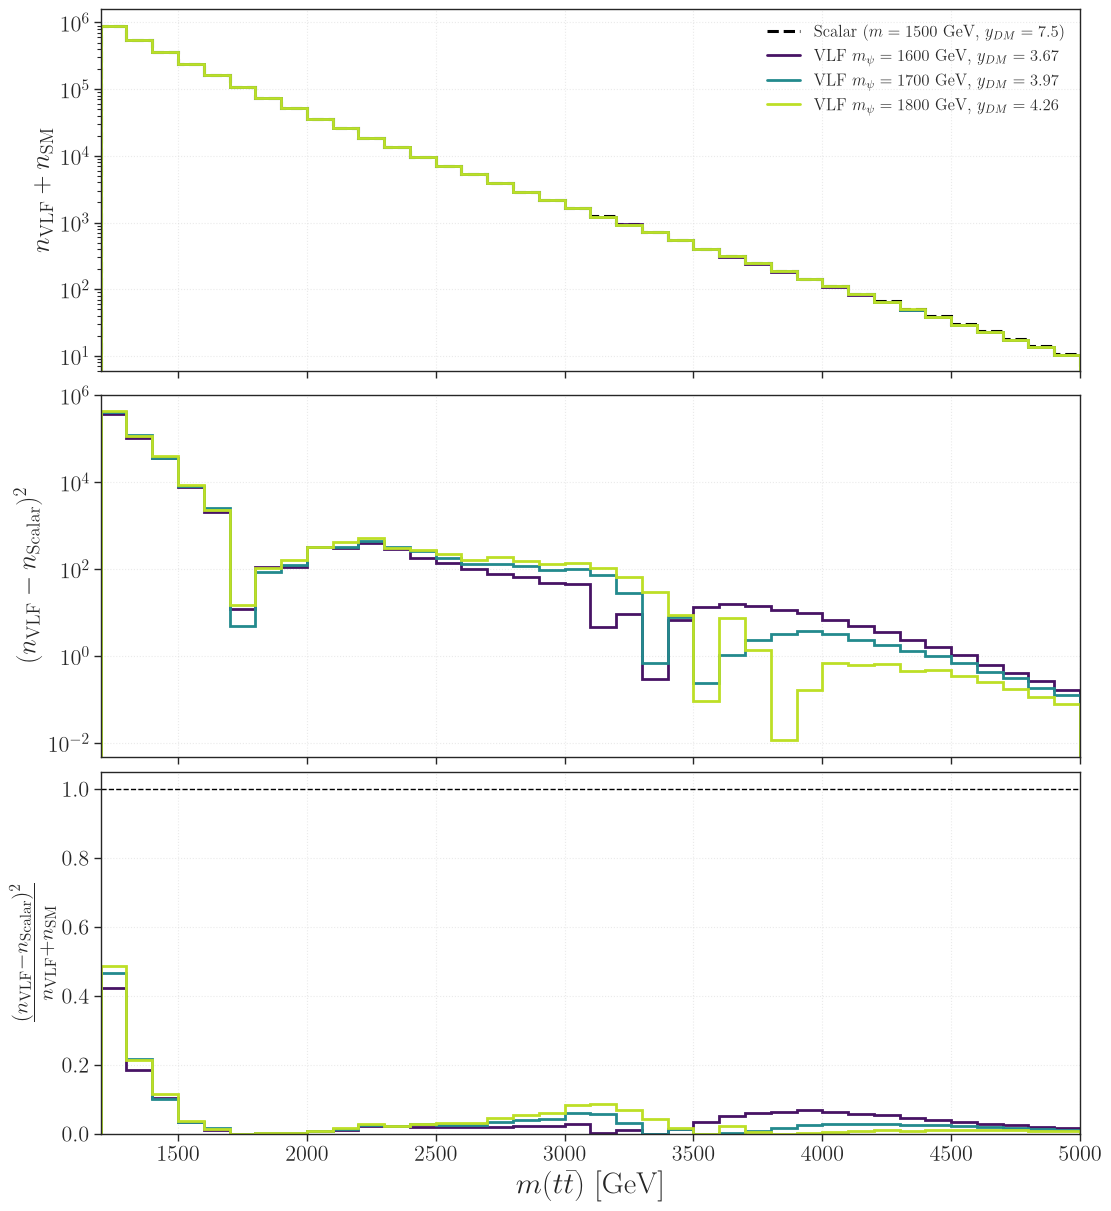

In [21]:
import glob
from collections import defaultdict

import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import minimize_scalar


# ============================================================
# Configuration
# ============================================================

LUMI_FB = 500.0
LUM = LUMI_FB * 1000.0       # pb x fb^-1 -> events

VAR = "mTT"
ANALYSIS_RANGE = (1200.0, 5000.0)
BINS = np.arange(1200.0, 5100.0, 100.0)

SCALAR_MASS = 1500.0
SCALAR_DM_MASS = 1400.0
SCALAR_YDM = 7.5

VLF_YDM_BOUNDS = (0.0, 10.1)

# None = use every available VLF mass.
# Example: [1000, 1500, 1700, 2000]
VLF_MASSES = [1600, 1700, 1800]

BSM_GLOB = (
    "/home/vinicius/EFT_ToyModel/processFolders/"
    "Distributions_13_6TeV/bias/*/*/*.npz"
)

# Adjust this path if your 13.6 TeV SM files are elsewhere.
SM_GLOB = (
    "/home/vinicius/EFT_ToyModel/processFolders/"
    "Distributions_13_6TeV/bias/sm/pp2ttbar_gs4/*.npz"
)


# ============================================================
# Load data
# ============================================================

def load_npz_files(pattern, recursive=False):
    paths = sorted(glob.glob(pattern, recursive=recursive))
    if not paths:
        raise FileNotFoundError(f"No files found for: {pattern}")

    datasets = []
    for path in paths:
        with np.load(path, allow_pickle=True) as f:
            data = {key: f[key] for key in f.files}
        data["_source_file"] = path
        datasets.append(data)

    return datasets


def model_name(data):
    return str(np.asarray(data["model"]).reshape(-1)[0])


def mass_pair(data):
    values = np.asarray(data["mass_params"], dtype=float).reshape(-1)
    return float(values[0]), float(values[1])


def load_bsm_mass_scan(pattern):
    """
    Group the scalar and VLF samples by model and mass parameters.
    All samples belonging to a group are treated as additive
    contributions (e.g. qq and gg).
    """
    files = load_npz_files(pattern, recursive=True)
    grouped = defaultdict(list)

    for data in files:
        if "model" not in data or "mass_params" not in data:
            continue

        name = model_name(data)
        if "Scalar" in name:
            model = "Scalar"
        elif "VLF" in name:
            model = "VLF"
        else:
            continue

        grouped[(model, *mass_pair(data))].append(data)

    return grouped


def compute_hist(data_list, bins, var=VAR, weight_factor=1.0, average=False):
    hist = np.zeros(len(bins) - 1, dtype=float)

    for data in data_list:
        x = np.asarray(data[var], dtype=float)
        weights = np.asarray(data["weights"], dtype=float) * weight_factor

        if x.shape != weights.shape:
            raise ValueError(f"Shape mismatch in {data['_source_file']}")

        hist += np.histogram(x, bins=bins, weights=weights)[0]

    if average and len(data_list) > 0:
        hist /= len(data_list)

    return hist


# ============================================================
# VLF best fit
# ============================================================

def vlf_hist(y_dm, h_vlf_unit):
    return y_dm**2 * h_vlf_unit


def vlf_objective(y_dm, h_vlf_unit, h_scalar, h_sm, fit_mask):
    """
    Luminosity-independent objective:

        Q/L = sum [(h_VLF - h_Scalar)^2 / (h_SM + h_VLF)]

    All h are cross-section histograms in pb.

    The physical statistic is Q = L * (Q/L).
    """
    h_vlf = vlf_hist(y_dm, h_vlf_unit)
    denominator = (h_sm + h_vlf)[fit_mask]
    difference = (h_vlf - h_scalar)[fit_mask]

    if np.any(~np.isfinite(denominator)) or np.any(denominator <= 0):
        return np.inf

    return float(np.sum(difference**2 / denominator))


def fit_vlf(h_vlf_unit, h_scalar, h_sm, fit_mask,
            y_bounds=VLF_YDM_BOUNDS):
    """
    Scan the coupling and refine all visible local minima.

    This avoids assuming that the objective has only one minimum.
    """
    y_grid = np.linspace(*y_bounds, 1001)
    q_grid = np.array([
        vlf_objective(y, h_vlf_unit, h_scalar, h_sm, fit_mask)
        for y in y_grid
    ])

    finite = np.isfinite(q_grid)
    if not finite.any():
        raise RuntimeError("No valid VLF coupling in the requested range.")

    candidates = set()

    for i in np.flatnonzero(finite):
        left = q_grid[i - 1] if i > 0 else np.inf
        right = q_grid[i + 1] if i < len(q_grid) - 1 else np.inf

        if q_grid[i] <= left and q_grid[i] <= right:
            candidates.add(int(i))

    candidates.add(int(np.nanargmin(q_grid)))

    best_y = None
    best_q = np.inf

    for i in sorted(candidates):
        y = float(y_grid[i])
        q = float(q_grid[i])

        if q < best_q:
            best_y, best_q = y, q

        if 0 < i < len(y_grid) - 1 and np.isfinite(q_grid[i-1:i+2]).all():
            result = minimize_scalar(
                vlf_objective,
                bounds=(y_grid[i-1], y_grid[i+1]),
                method="bounded",
                args=(h_vlf_unit, h_scalar, h_sm, fit_mask),
                options={"xatol": 1e-9},
            )

            if result.success and np.isfinite(result.fun) and result.fun < best_q:
                best_y, best_q = float(result.x), float(result.fun)

    h_best = vlf_hist(best_y, h_vlf_unit)
    n_best = LUM * h_best
    n_scalar = LUM * h_scalar
    n_sm = LUM * h_sm

    denominator = n_sm + n_best
    numerator = (n_best - n_scalar)**2

    ratio = np.full(len(h_best), np.nan)
    valid = fit_mask & np.isfinite(denominator) & (denominator > 0)
    ratio[valid] = numerator[valid] / denominator[valid]

    return {
        "y_dm": best_y,
        "weight_factor": best_y**2,
        "objective": LUM * best_q,
        "hist": h_best,
        "denominator": denominator,
        "numerator": numerator,
        "ratio": ratio,
    }


# ============================================================
# Load 13.6 TeV samples
# ============================================================

bsm_groups = load_bsm_mass_scan(BSM_GLOB)
data_sm_exp = load_npz_files(SM_GLOB)

scalar_key = ("Scalar", SCALAR_MASS, SCALAR_DM_MASS)

if scalar_key not in bsm_groups:
    raise RuntimeError(
        f"Scalar reference {scalar_key} not found. "
        "Check BSM_GLOB and the mass_params metadata."
    )

scalar_samples = bsm_groups[scalar_key]

vlf_groups = {
    (m_partner, m_dm): samples
    for (model, m_partner, m_dm), samples in bsm_groups.items()
    if model == "VLF"
    and (VLF_MASSES is None or m_partner in VLF_MASSES)
}

if not vlf_groups:
    raise RuntimeError("No VLF samples found for the selected masses.")

print("Scalar benchmark:", scalar_key)
print("Scalar samples:", len(scalar_samples))
print("\nAvailable VLF masses:")
for masses, samples in sorted(vlf_groups.items()):
    print(f"  {masses[0]:.0f}, {masses[1]:.0f} GeV: {len(samples)} samples")


# ============================================================
# Build reference histograms
# ============================================================

fit_mask = (
    (BINS[:-1] >= ANALYSIS_RANGE[0])
    & (BINS[1:] <= ANALYSIS_RANGE[1])
)

# Multiple SM files are assumed to be independent replicas.
h_sm = compute_hist(data_sm_exp, BINS, average=True)

# Scalar qq + gg at fixed y_DM = 7.5
h_scalar = compute_hist(
    scalar_samples, BINS, weight_factor=SCALAR_YDM**2
)

if np.any((h_sm + h_scalar)[fit_mask] <= 0):
    raise RuntimeError("Scalar + SM expectation is nonpositive in a fit bin.")


# ============================================================
# Fit every VLF mass
# ============================================================

vlf_results = {}

for (m_partner, m_dm), samples in sorted(vlf_groups.items()):
    h_vlf_unit = compute_hist(samples, BINS)

    result = fit_vlf(h_vlf_unit, h_scalar, h_sm, fit_mask)
    vlf_results[(m_partner, m_dm)] = result

    print(
        f"VLF m = {m_partner:.0f} GeV, "
        f"mDM = {m_dm:.0f} GeV | "
        f"best yDM = {result['y_dm']:.6f} | "
        f"Q = {result['objective']:.6f}"
    )


# ============================================================
# Three-panel plot
# ============================================================

fig, ax = plt.subplots(
    3, 1, figsize=(11, 12), sharex=True, constrained_layout=True
)

scalar_total = LUM * (h_sm + h_scalar)
scalar_plot = np.where(
    fit_mask & (scalar_total > 0), scalar_total, np.nan
)

ax[0].stairs(
    scalar_plot, BINS, color="black", linestyle="--",
    linewidth=2.2,
    label=rf"Scalar ($m={SCALAR_MASS:.0f}$ GeV, $y_{{DM}}={SCALAR_YDM:g}$)"
)

colors = plt.cm.viridis(np.linspace(0.05, 0.9, len(vlf_results)))

for color, ((m_partner, m_dm), result) in zip(colors, vlf_results.items()):
    label = rf"VLF $m_\psi={m_partner:.0f}$ GeV, $y_{{DM}}={result['y_dm']:.2f}$"

    denominator = np.where(
        fit_mask & (result["denominator"] > 0),
        result["denominator"], np.nan
    )
    numerator = np.where(
        fit_mask & (result["numerator"] > 0),
        result["numerator"], np.nan
    )

    ax[0].stairs(denominator, BINS, color=color, linewidth=2, label=label)
    ax[1].stairs(numerator, BINS, color=color, linewidth=2)
    ax[2].stairs(result["ratio"], BINS, color=color, linewidth=2)

ax[0].set_ylabel(r"$n_{\rm VLF}+n_{\rm SM}$", fontsize=19)
ax[1].set_ylabel(r"$(n_{\rm VLF}-n_{\rm Scalar})^2$", fontsize=19)
ax[2].set_ylabel(
    r"$\frac{(n_{\rm VLF}-n_{\rm Scalar})^2}{n_{\rm VLF}+n_{\rm SM}}$",
    fontsize=22
)
ax[2].set_xlabel(r"$m(t\bar{t})$ [GeV]", fontsize=22)

ax[0].set_yscale("log")
ax[1].set_yscale("log")
ax[2].axhline(1.0, color="black", linestyle="--", linewidth=1)

for a in ax:
    a.set_xlim(ANALYSIS_RANGE)
    a.grid(True, linestyle=":", alpha=0.4)
    a.tick_params(axis="both", labelsize=16)

ax[0].legend(frameon=False, fontsize=12)
plt.show()